In [45]:
# Loading necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats.mstats import winsorize
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import kruskal
from scipy.stats import spearmanr


# Data Preparation
# Load dataset
file_path = '../data/Superstore.csv'
df = pd.read_csv(file_path, encoding='latin1')

# Display basic information about the dataset
print("\nDataset unique, top and frq of top values:\n")
print(df.describe(include='O'))
print("\n")

print("\n\nDataset Overview (variable type):\n")
print(df.info())
print("\n")

print("\nFirst few rows:")
print(df.head())
print("\n")

print("\nShipping modes: ")
print(df['Ship Mode'].unique())
print("\n")

print("Countries: ")
print(df['Country'].unique())
print("\n")

print('Number of states: ' + str(df['State'].unique().shape[0]))
print("\n")

print("Region: ")
print(df['Region'].unique())
print("\n")

print('Number of cities: ' + str(df['City'].unique().shape[0]))
print("\n")

print("Categories: ")
print(df['Category'].unique())
print("\n")

print("Number of Sub categories: " + str(df['Sub-Category'].unique().shape[0]))
print(df['Sub-Category'].unique())

print("\n")

print("Number of Products: " + str(df['Product ID'].unique().shape[0]))
print("\n")


Dataset unique, top and frq of top values:

              Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
count             9994        9994        9994            9994        9994   
unique            5009        1237        1334               4         793   
top     CA-2017-100111  09/05/2016  12/16/2015  Standard Class    WB-21850   
freq                14          38          35            5968          37   

        Customer Name   Segment        Country           City       State  \
count            9994      9994           9994           9994        9994   
unique            793         3              1            531          49   
top     William Brown  Consumer  United States  New York City  California   
freq               37      5191           9994            915        2001   

       Region       Product ID         Category Sub-Category     Product Name  
count    9994             9994             9994         9994             9994  
unique      4     

In [46]:
# Removing unnecessary columns
columns_to_drop = ['Country', 'Customer Name', 'Postal Code', 'Row ID']
df.drop(columns=columns_to_drop, inplace=True)
print(f"Removed columns: {columns_to_drop}")
print(df.head())

Removed columns: ['Country', 'Customer Name', 'Postal Code', 'Row ID']
         Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0  CA-2016-152156  11/08/2016  11/11/2016    Second Class    CG-12520   
1  CA-2016-152156  11/08/2016  11/11/2016    Second Class    CG-12520   
2  CA-2016-138688  06/12/2016   6/16/2016    Second Class    DV-13045   
3  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Segment             City       State Region       Product ID  \
0   Consumer        Henderson    Kentucky  South  FUR-BO-10001798   
1   Consumer        Henderson    Kentucky  South  FUR-CH-10000454   
2  Corporate      Los Angeles  California   West  OFF-LA-10000240   
3   Consumer  Fort Lauderdale     Florida  South  FUR-TA-10000577   
4   Consumer  Fort Lauderdale     Florida  South  OFF-ST-10000760   

          Category Sub-Category  \
0        Furniture    Bookcases   
1    

In [47]:
# Checking for duplicate rows and removing
duplicate_count1 = df.duplicated().sum()

# Display duplicates
if duplicate_count1 > 0:
    print("Duplicate Rows Sample:")
    display(df[df.duplicated()])

df = df.drop_duplicates()

duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count1}")
print(f"Number of duplicate rows after removing: {duplicate_count}")

Duplicate Rows Sample:


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,City,State,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
3406,US-2014-150119,4/23/2014,4/27/2014,Standard Class,LB-16795,Home Office,Columbus,Ohio,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588


Number of duplicate rows: 1
Number of duplicate rows after removing: 0


In [48]:
#  Data Integration is not required
# Since we only have one dataset, no merging is required.
# If additional data sources were available, we would merge them

In [87]:
# distribution of categorical variables
ship_mode = go.Histogram(x=df["Ship Mode"],name="Ship Mode")
segment = go.Histogram(x=df["Segment"],name="Segment")
Region = go.Histogram(x=df["Region"],name="Region")
category = go.Histogram(x=df["Category"],name="Category")

fig = make_subplots(rows=2, cols=2)
fig.append_trace(ship_mode, row = 1, col = 1)
fig.append_trace(segment, row = 1, col = 2)
fig.append_trace(Region, row = 2, col = 1)
fig.append_trace(category, row = 2, col = 2)
fig.update_layout(
    title_text = 'Number of occurrences of each categorical variable',
    title_x=0.45
)
fig.show()

[interactive Plotly figure - run the notebook to view]

In [49]:
# Check for missing values
missing_values = df.isnull().sum()
print("\nMissing Values:")
print(df.isnull().sum().sum())


Missing Values:
0


In [50]:
# Save cleaned dataset for next steps
df.to_csv('../data/Clean_Superstore.csv', index=False)
print("\nData Preparation Completed! Cleaned dataset saved.")


Data Preparation Completed! Cleaned dataset saved.


In [51]:
# Descriptive Statistics

# Load cleaned dataset
df = pd.read_csv('../data/Clean_Superstore.csv')

# Adding New Features
df['Profit Margin (%)'] = ((df['Profit']/df['Quantity']) / ((df['Sales'] - df['Profit']) / df['Quantity'])) * 100
df['Profit per Order'] = df['Profit'] / df['Quantity']

df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')

#delivery day
df['Delivery Days'] = df['Ship Date'] - df['Order Date']
df['Delivery Days']=df['Delivery Days'].dt.days
df.info()

df_moj = df.copy()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9993 entries, 0 to 9992
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Order ID           9993 non-null   object        
 1   Order Date         9993 non-null   datetime64[ns]
 2   Ship Date          9993 non-null   datetime64[ns]
 3   Ship Mode          9993 non-null   object        
 4   Customer ID        9993 non-null   object        
 5   Segment            9993 non-null   object        
 6   City               9993 non-null   object        
 7   State              9993 non-null   object        
 8   Region             9993 non-null   object        
 9   Product ID         9993 non-null   object        
 10  Category           9993 non-null   object        
 11  Sub-Category       9993 non-null   object        
 12  Product Name       9993 non-null   object        
 13  Sales              9993 non-null   float64       
 14  Quantity

In [53]:
#What is distribution of sales over the past years?
df['Year'] = df['Order Date'].dt.year

# Group sales by year
yearly_sales = df.groupby('Year')['Profit'].sum().reset_index()

# Create a line plot for sales over the years
fig = px.line(yearly_sales, x='Year', y='Profit', markers=True)

fig.update_layout(
    title='Distribution of Profit Over the Years',
    title_x=0.45,
    width=1300,
    title_font=dict(size=24, family="Arial", color="black"),
    xaxis_title="Year",
    yaxis_title="Total Profit",
    template="plotly_white"
)

fig.show()

[interactive Plotly figure - run the notebook to view]

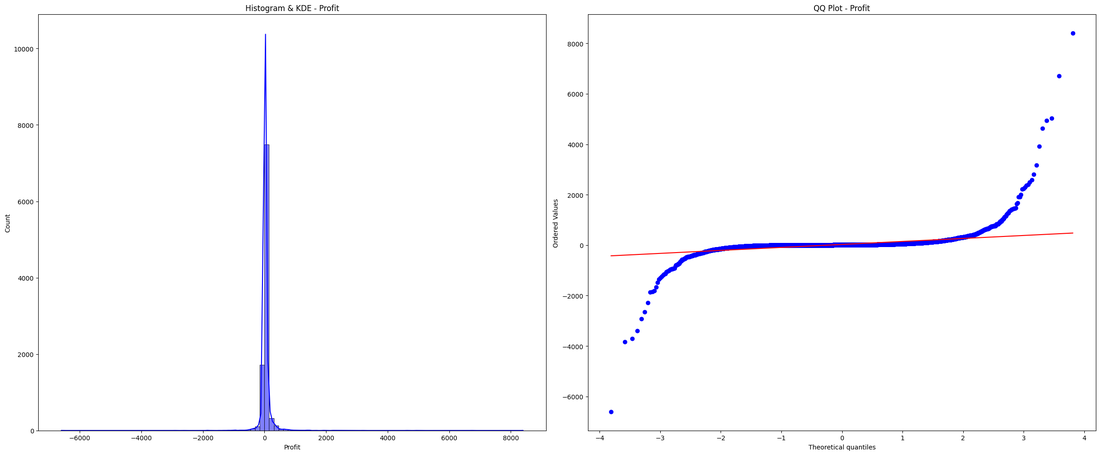

D’Agostino’s K-Squared Test: Statistic=14361.9124, P-Value=0.0000e+00
 Profit is NOT normally distributed.


In [54]:
# (Histogram & QQ Plot)
plt.figure(figsize=(24, 10))

# Histogram with KDE
plt.subplot(1, 2, 1)
sns.histplot(df_moj['Profit'], kde=True, bins=100, color='blue')
plt.title("Histogram & KDE - Profit")

# QQ Plot
plt.subplot(1, 2, 2)
stats.probplot(df_moj['Profit'], dist="norm", plot=plt)
plt.title("QQ Plot - Profit")
plt.tight_layout()
plt.show()

# Best Normality Test for Large Data (D’Agostino’s K-Squared Test)
stat, p = stats.normaltest(df_moj['Profit'])
print(f"D’Agostino’s K-Squared Test: Statistic={stat:.4f}, P-Value={p:.4e}")

# Interpretation
if p > 0.05:
    print(" Profit is normally distributed.")
else:
    print(" Profit is NOT normally distributed.")

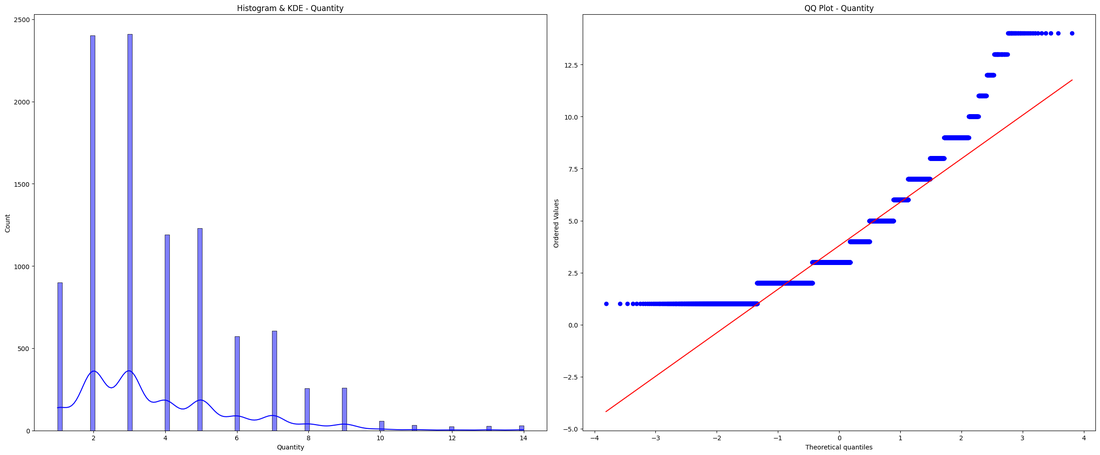

D’Agostino’s K-Squared Test: Statistic=2147.4905, P-Value=0.0000e+00
 Quantity is NOT normally distributed.


In [55]:
# (Histogram & QQ Plot)
plt.figure(figsize=(24, 10))

# Histogram with KDE
plt.subplot(1, 2, 1)
sns.histplot(df_moj['Quantity'], kde=True, bins=100, color='blue')
plt.title("Histogram & KDE - Quantity")

# QQ Plot
plt.subplot(1, 2, 2)
stats.probplot(df_moj['Quantity'], dist="norm", plot=plt)
plt.title("QQ Plot - Quantity")
plt.tight_layout()
plt.show()

# Best Normality Test for Large Data (D’Agostino’s K-Squared Test)
stat, p = stats.normaltest(df_moj['Quantity'])
print(f"D’Agostino’s K-Squared Test: Statistic={stat:.4f}, P-Value={p:.4e}")

# Interpretation
if p > 0.05:
    print(" Quantity is normally distributed.")
else:
    print(" Quantity is NOT normally distributed.")

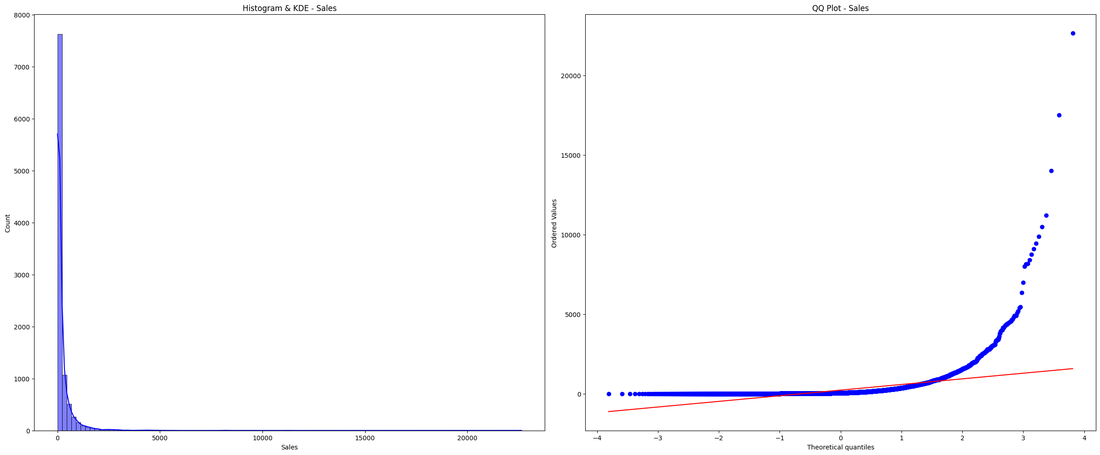

D’Agostino’s K-Squared Test: Statistic=18031.0897, P-Value=0.0000e+00
 Sales is NOT normally distributed.


In [56]:
# (Histogram & QQ Plot)
plt.figure(figsize=(24, 10))

# Histogram with KDE
plt.subplot(1, 2, 1)
sns.histplot(df_moj['Sales'], kde=True, bins=100, color='blue')
plt.title("Histogram & KDE - Sales")

# QQ Plot
plt.subplot(1, 2, 2)
stats.probplot(df_moj['Sales'], dist="norm", plot=plt)
plt.title("QQ Plot - Sales")
plt.tight_layout()
plt.show()

# Best Normality Test for Large Data (D’Agostino’s K-Squared Test)
stat, p = stats.normaltest(df_moj['Sales'])
print(f"D’Agostino’s K-Squared Test: Statistic={stat:.4f}, P-Value={p:.4e}")

# Interpretation
if p > 0.05:
    print(" Sales is normally distributed.")
else:
    print(" Sales is NOT normally distributed.")

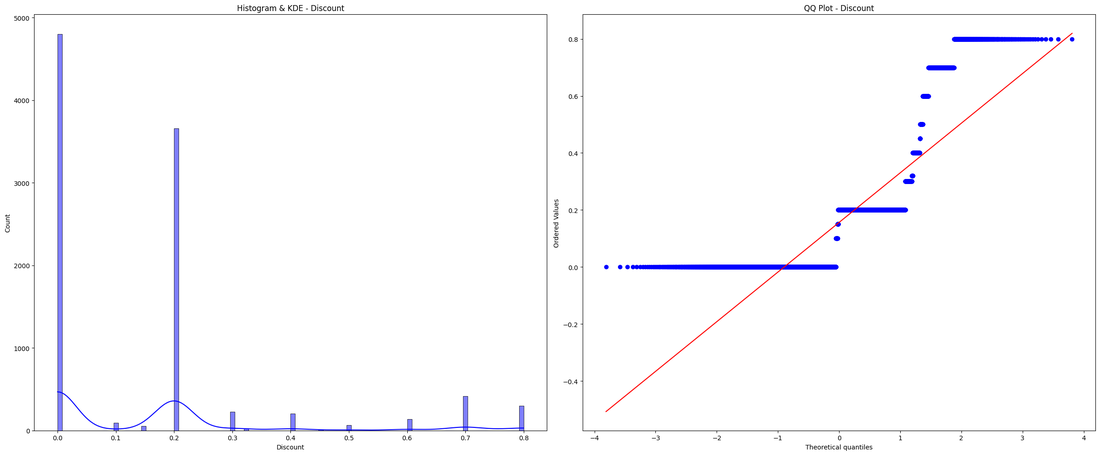

D’Agostino’s K-Squared Test: Statistic=2978.0053, P-Value=0.0000e+00
 Discount is NOT normally distributed.


In [57]:
# (Histogram & QQ Plot)
plt.figure(figsize=(24, 10))

# Histogram with KDE
plt.subplot(1, 2, 1)
sns.histplot(df_moj['Discount'], kde=True, bins=100, color='blue')
plt.title("Histogram & KDE - Discount")

# QQ Plot
plt.subplot(1, 2, 2)
stats.probplot(df_moj['Discount'], dist="norm", plot=plt)
plt.title("QQ Plot - Discount")
plt.tight_layout()
plt.show()

# Best Normality Test for Large Data (D’Agostino’s K-Squared Test)
stat, p = stats.normaltest(df_moj['Discount'])
print(f"D’Agostino’s K-Squared Test: Statistic={stat:.4f}, P-Value={p:.4e}")

# Interpretation
if p > 0.05:
    print(" Discount is normally distributed.")
else:
    print(" Discount is NOT normally distributed.")

Kruskal-Wallis Test: Statistic=4.4660, P-Value=0.1072
No significant difference in profit distribution across customer segments.





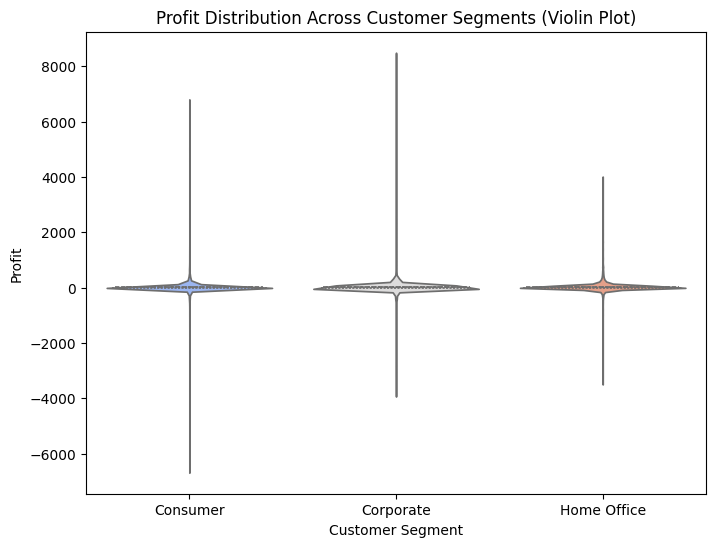

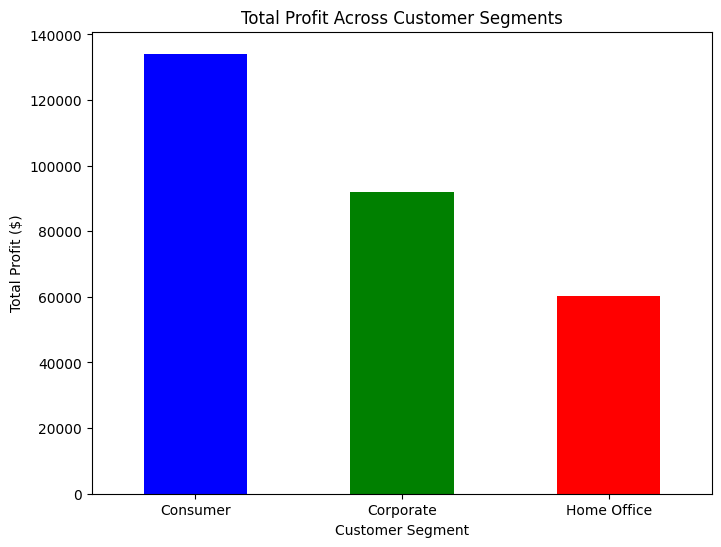

In [58]:
segments = df_moj['Segment'].unique()

# Group profit values by segment
profit_groups = [df_moj[df_moj['Segment'] == segment]['Profit'] for segment in segments]

# Perform Kruskal-Wallis Test
kw_stat, kw_p = kruskal(*profit_groups)

# Display Results
print(f"Kruskal-Wallis Test: Statistic={kw_stat:.4f}, P-Value={kw_p:.4f}")
if kw_p < 0.05:
    print("Significant difference in profit distribution across customer segments!")
else:
    print("No significant difference in profit distribution across customer segments.")
print("\n\n")

# Violin Plot: Shows Density + Distribution
plt.figure(figsize=(8,6))
sns.violinplot(x='Segment', y='Profit', data=df_moj, hue='Segment', inner="quartile", palette="coolwarm")
plt.title("Profit Distribution Across Customer Segments (Violin Plot)")
plt.xlabel("Customer Segment")
plt.ylabel("Profit")
plt.show()
print("\n\n")

# Total Profit vs. Customer Segment (Bar Chart)
plt.figure(figsize=(8,6))
df.groupby('Segment')['Profit'].sum().sort_values(ascending=False).plot(kind='bar', color=['blue', 'green', 'red'])
plt.title("Total Profit Across Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.show()

Kruskal-Wallis Test: Statistic=445.6099, P-Value=1.7260e-97
Significant difference in profit distribution across product categories!





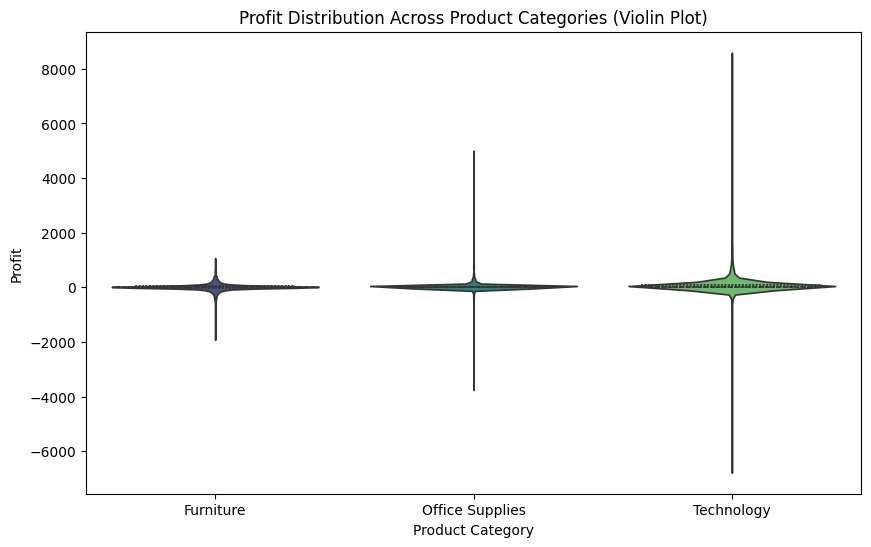

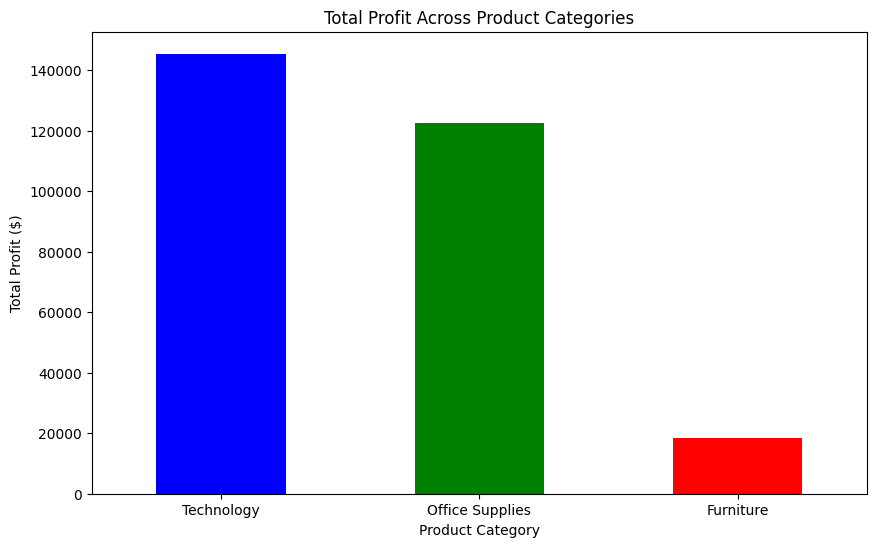

In [59]:
categories = df_moj['Category'].unique()

# Group profit values by category
profit_groups = [df_moj[df_moj['Category'] == cat]['Profit'] for cat in categories]

# Perform Kruskal-Wallis Test
kw_stat, kw_p = kruskal(*profit_groups)

# Display Results
print(f"Kruskal-Wallis Test: Statistic={kw_stat:.4f}, P-Value={kw_p:.4e}")
if kw_p < 0.05:
    print("Significant difference in profit distribution across product categories!")
else:
    print("No significant difference in profit distribution across product categories.")
print("\n\n")

# Violin Plot: Profit Distribution with Density
plt.figure(figsize=(10,6))
sns.violinplot(x="Category", y="Profit", hue="Category", data=df_moj, inner="quartile", palette="viridis", legend=False)
plt.title("Profit Distribution Across Product Categories (Violin Plot)")
plt.xlabel("Product Category")
plt.ylabel("Profit")
plt.show()
print("\n\n")

# Total Profit vs. Product Category (Bar Chart)
plt.figure(figsize=(10,6))
df.groupby('Category')['Profit'].sum().sort_values(ascending=False).plot(kind='bar', color=['blue', 'green', 'red'])
plt.title("Total Profit Across Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.show()

Kruskal-Wallis H Test: Statistic=1195.6812, P-Value=1.2586e-244
Significant difference in profit distribution across sub-categories!





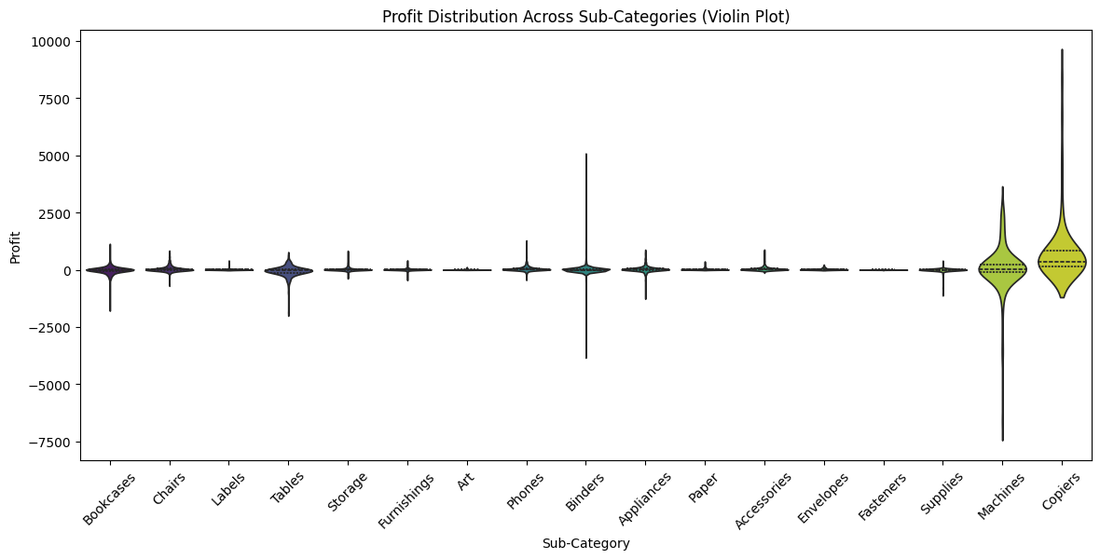

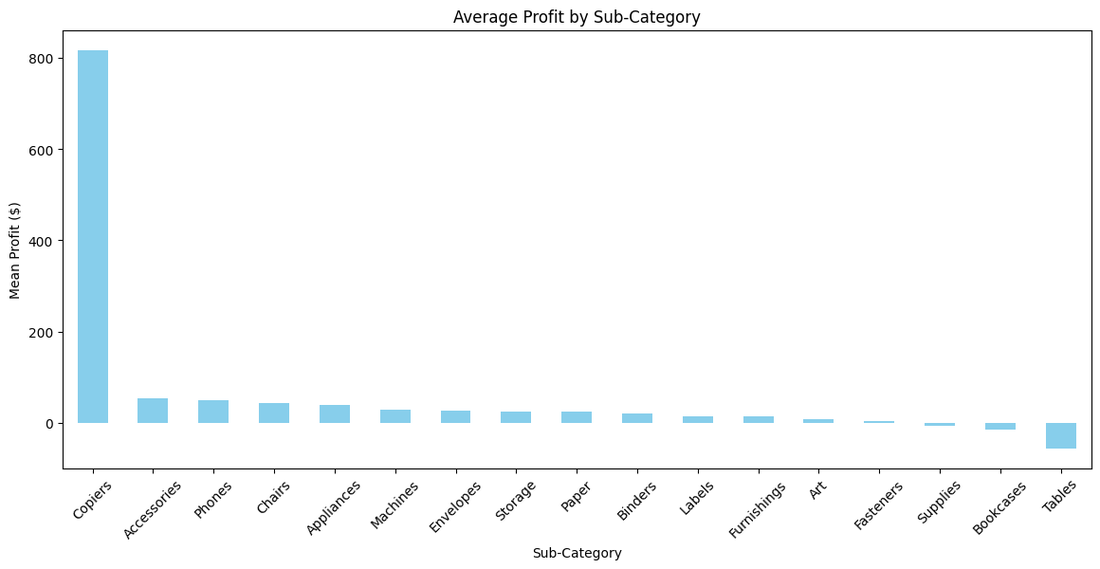

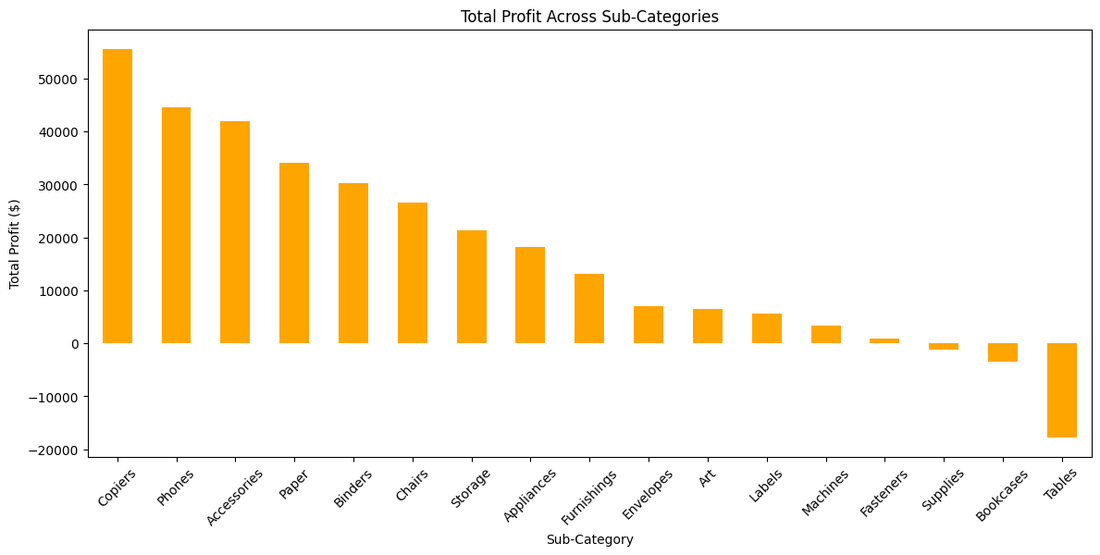

In [60]:
sub_categories = df_moj['Sub-Category'].unique()

# Group profit values by sub-category
profit_groups = [df_moj[df_moj['Sub-Category'] == sub]['Profit'] for sub in sub_categories]

# Perform Kruskal-Wallis Test
kw_stat, kw_p = kruskal(*profit_groups)

# Display Results
print(f"Kruskal-Wallis H Test: Statistic={kw_stat:.4f}, P-Value={kw_p:.4e}")
if kw_p < 0.05:
    print("Significant difference in profit distribution across sub-categories!")
else:
    print("No significant difference in profit distribution across sub-categories.")
print("\n\n")

# Violin Plot: Profit Distribution Across Sub-Categories
plt.figure(figsize=(14,6))
sns.violinplot(x="Sub-Category", y="Profit", hue="Sub-Category", data=df_moj, inner="quartile", palette="viridis", legend=False)
plt.xticks(rotation=45)
plt.title("Profit Distribution Across Sub-Categories (Violin Plot)")
plt.xlabel("Sub-Category")
plt.ylabel("Profit")
plt.show()
print("\n\n")

# Bar Chart: Mean Profit by Sub-Category
plt.figure(figsize=(14,6))
df.groupby('Sub-Category')['Profit'].mean().sort_values(ascending=False).plot(kind='bar', color='skyblue')
plt.title("Average Profit by Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Mean Profit ($)")
plt.xticks(rotation=45)
plt.show()
print("\n\n")

# Bar Chart: Total Profit by Sub-Category
plt.figure(figsize=(14,6))
df.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=False).plot(kind='bar', color='orange')
plt.title("Total Profit Across Sub-Categories")
plt.xlabel("Sub-Category")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=45)
plt.show()

In [61]:
# Histogram of Number of Different Products Sold per Sub-Category
fig = px.histogram(df, y="Sub-Category", color="Product ID").update_yaxes(categoryorder='total ascending')
fig.update_layout(
    title_text="Number of Different Products Sold per Sub-Category (Histogram)",
    title_x=0.5,
    title_font=dict(size=16)
)
fig.show()
print("The company sell more than a 1000 different types of 'Binders' and 'Papers'.\nBetween 500 and 1000 different types of 'Phones', 'Storage', 'Art', 'Accesories' and 'Chairs'.\nBetween 500 and 200 different types of 'Appliances', 'Lables', 'Tables', 'Envelopes', 'Bookcases', and 'Fasteners'.\nLess than 200 different types of 'Supplies', 'Machines', 'Copiers'.\nThere isn't a dominant product in each sub-category.")

[interactive Plotly figure - run the notebook to view]

The company sell more than a 1000 different types of 'Binders' and 'Papers'.
Between 500 and 1000 different types of 'Phones', 'Storage', 'Art', 'Accesories' and 'Chairs'.
Between 500 and 200 different types of 'Appliances', 'Lables', 'Tables', 'Envelopes', 'Bookcases', and 'Fasteners'.
Less than 200 different types of 'Supplies', 'Machines', 'Copiers'.
There isn't a dominant product in each sub-category.


Kruskal-Wallis H Test: Statistic=11.0771, P-Value=0.0113
Significant difference in profit distribution across shipping modes!





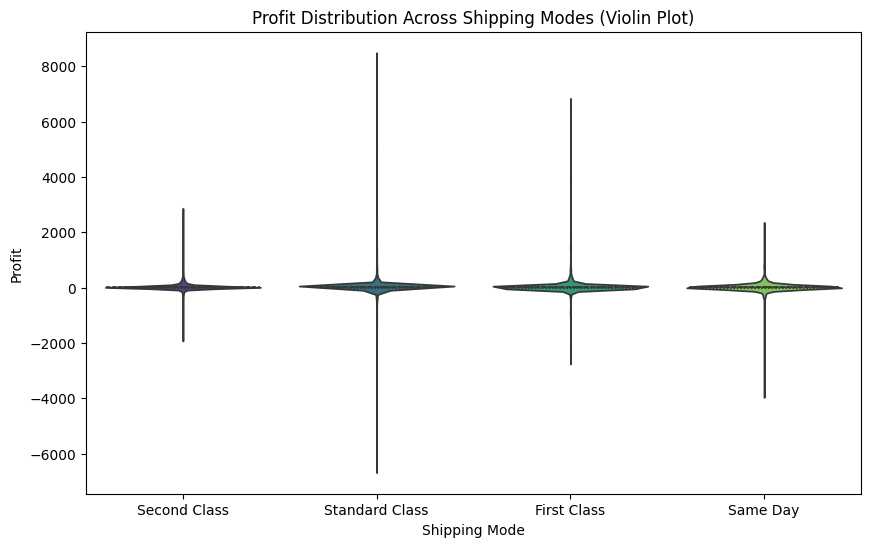

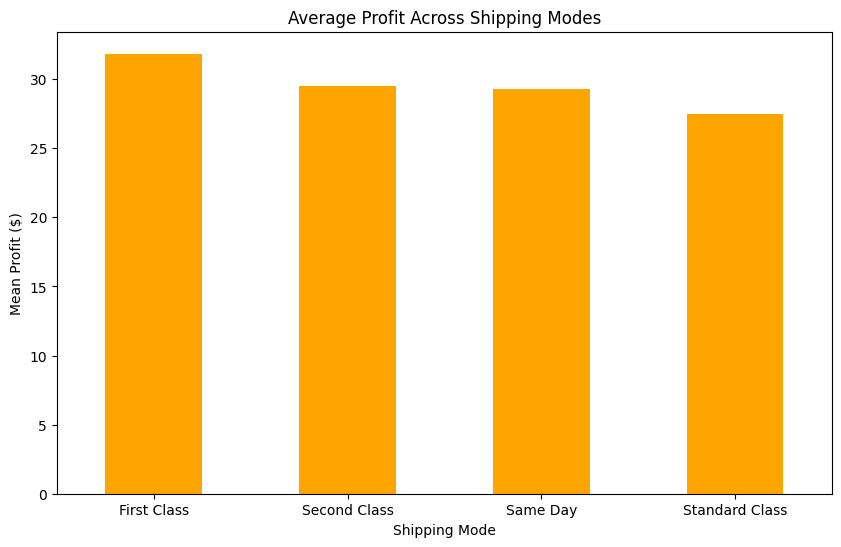

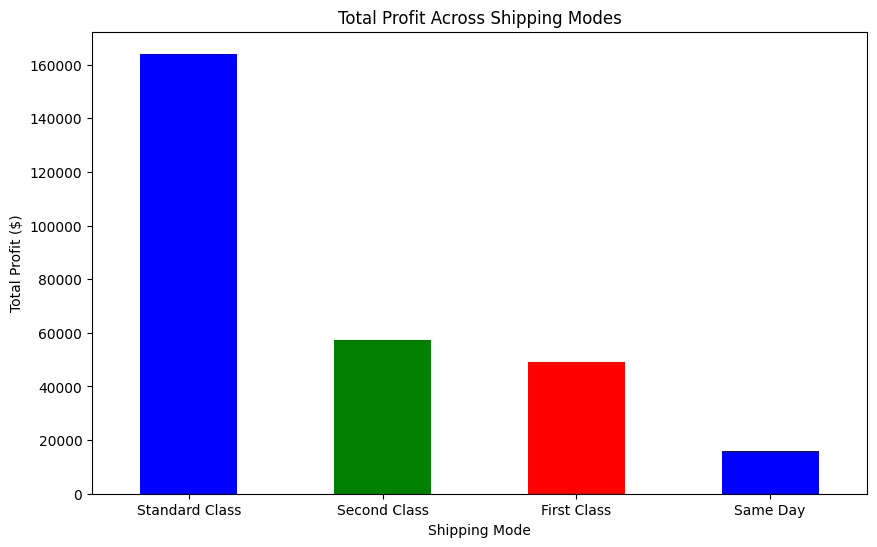

In [62]:
ship_modes = df_moj['Ship Mode'].unique()

# Group profit values by shipping mode
profit_groups = [df_moj[df_moj['Ship Mode'] == mode]['Profit'] for mode in ship_modes]

# Perform Kruskal-Wallis Test
kw_stat, kw_p = kruskal(*profit_groups)

# Display Results
print(f"Kruskal-Wallis H Test: Statistic={kw_stat:.4f}, P-Value={kw_p:.4f}")
if kw_p < 0.05:
    print("Significant difference in profit distribution across shipping modes!")
else:
    print("No significant difference in profit distribution across shipping modes.")
print("\n\n")

# Violin Plot: Profit Distribution with Density
plt.figure(figsize=(10,6))
sns.violinplot(x="Ship Mode", y="Profit", hue="Ship Mode", data=df_moj, inner="quartile", palette="viridis", legend=False)
plt.title("Profit Distribution Across Shipping Modes (Violin Plot)")
plt.xlabel("Shipping Mode")
plt.ylabel("Profit")
plt.show()
print("\n\n")

# Mean Profit vs. Shipping Mode (Bar Chart)
plt.figure(figsize=(10,6))
df.groupby('Ship Mode')['Profit'].mean().sort_values(ascending=False).plot(kind='bar', color='orange')
plt.title("Average Profit Across Shipping Modes")
plt.xlabel("Shipping Mode")
plt.ylabel("Mean Profit ($)")
plt.xticks(rotation=0)
plt.show()
print("\n\n")

# Total Profit vs. Shipping Mode (Bar Chart)
plt.figure(figsize=(10,6))
df.groupby('Ship Mode')['Profit'].sum().sort_values(ascending=False).plot(kind='bar', color=['blue', 'green', 'red'])
plt.title("Total Profit Across Shipping Modes")
plt.xlabel("Shipping Mode")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.show()

In [63]:
# How long each type of shipping mode take long?
box_fig = px.box(df, x='Ship Mode', y='Delivery Days', color='Ship Mode')
box_fig.update_layout(title="Impact of Ship Mode on Delivery Days",title_x=0.45,width=1300,title_font=dict(size=24, family="Arial", color="black"))
box_fig.show()

[interactive Plotly figure - run the notebook to view]

In [64]:
# Treemap of state and ship modes
state_ship_mode_counts = df.groupby(['State', 'Ship Mode']).size().reset_index(name='Count')
fig = px.treemap(state_ship_mode_counts, path=['State', 'Ship Mode'], values='Count')
fig.update_layout( title='Treemap of State vs. Ship Mode',title_x=0.45,width=1600,title_font=dict(size=24, family="Arial", color="black"))
fig.show()

[interactive Plotly figure - run the notebook to view]

Kruskal-Wallis H Test: Statistic=227.8351, P-Value=4.0633e-49
Significant difference in profit distribution across regions!





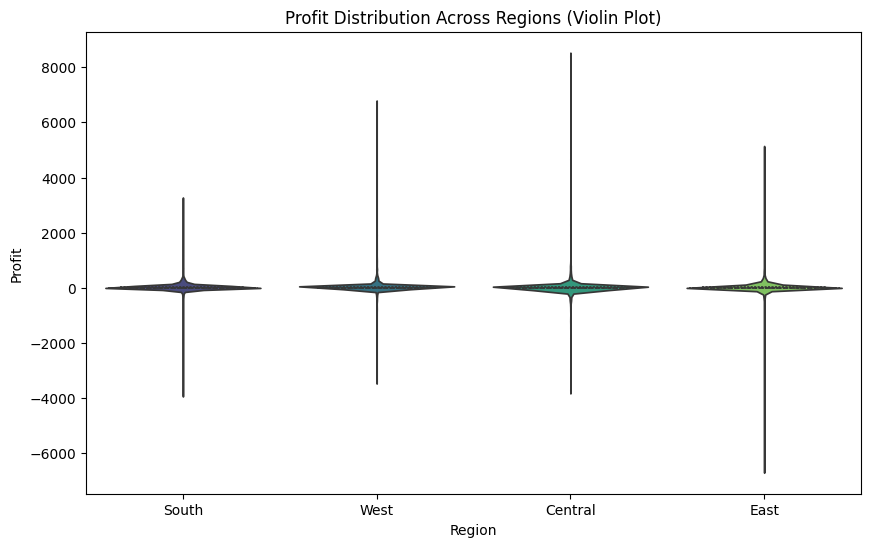

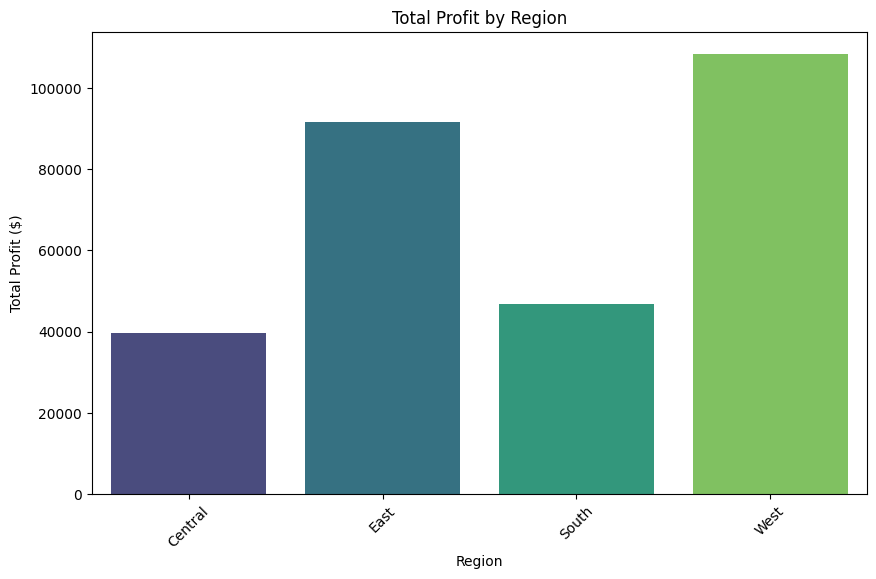

In [65]:
regions = df_moj['Region'].unique()
# Group profit values by region
profit_groups = [df_moj[df_moj['Region'] == reg]['Profit'] for reg in regions]

# Perform Kruskal-Wallis Test
kw_stat, kw_p = kruskal(*profit_groups)

# Display Results
print(f"Kruskal-Wallis H Test: Statistic={kw_stat:.4f}, P-Value={kw_p:.4e}")

if kw_p < 0.05:
    print("Significant difference in profit distribution across regions!")
else:
    print("No significant difference in profit distribution across regions.")
print("\n\n")

# Violin Plot: Profit Distribution Across Regions
plt.figure(figsize=(10,6))
sns.violinplot(x="Region", y="Profit", hue="Region", data=df_moj, inner="quartile", palette="viridis", legend=False)
plt.title("Profit Distribution Across Regions (Violin Plot)")
plt.xlabel("Region")
plt.ylabel("Profit")
plt.show()
print("\n\n")

region_profit = df.groupby('Region')['Profit'].sum().reset_index()
# Bar Plot: Total Profit by Region
plt.figure(figsize=(10, 6))
sns.barplot(x="Region", y="Profit", hue="Region", data=region_profit, palette="viridis", dodge=False)
plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=45)
plt.show()

Kruskal-Wallis Test: Statistic=2580.6790, P-Value=0.0000
Significant difference in profit distribution across states!





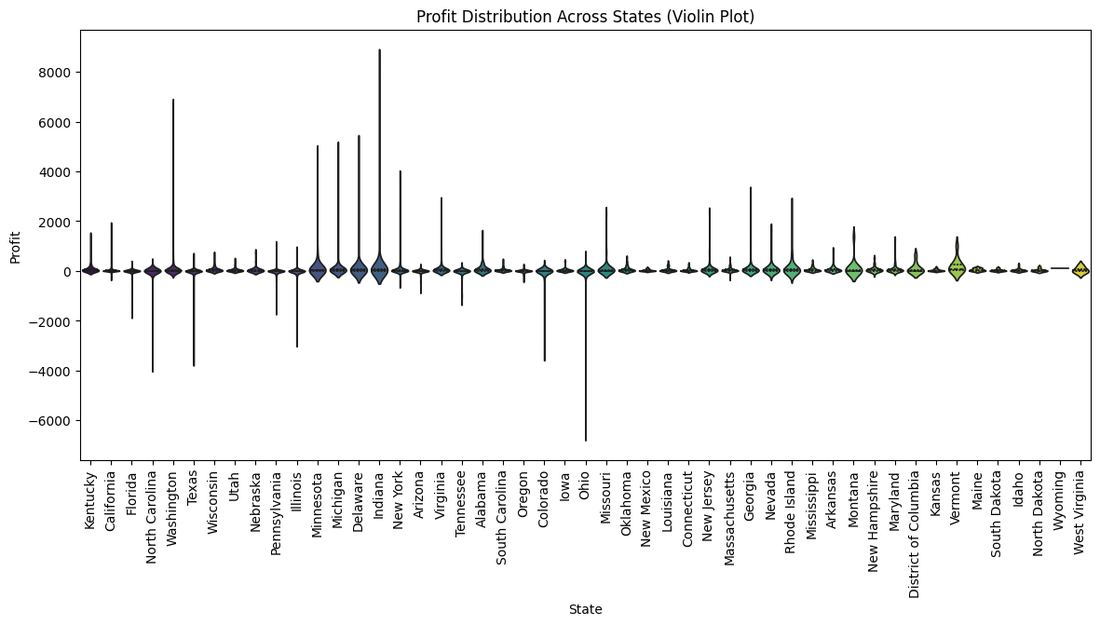

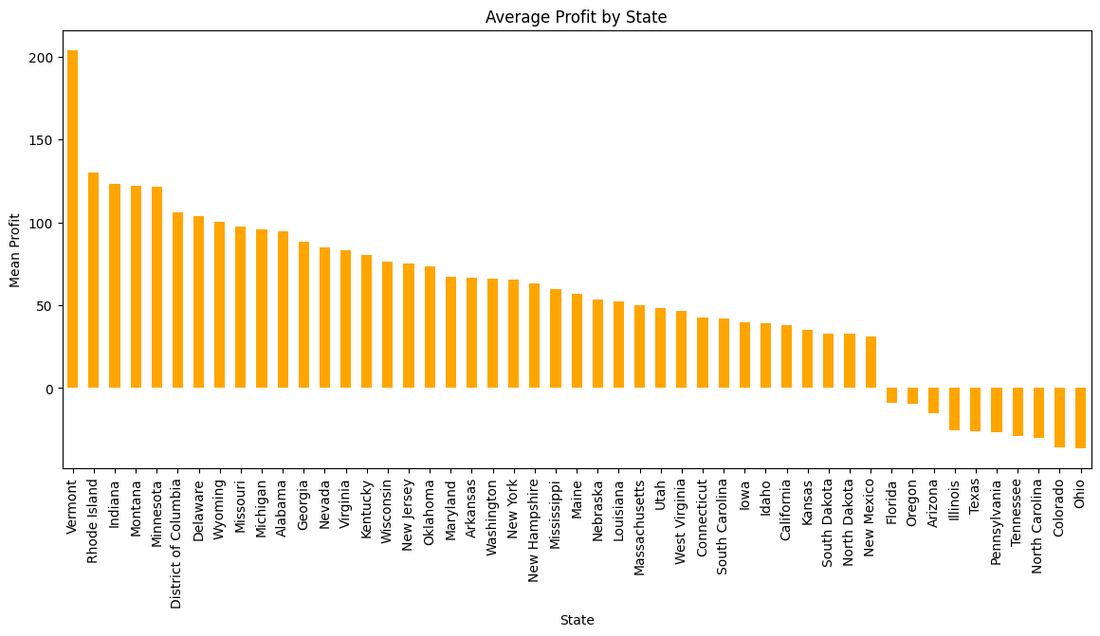

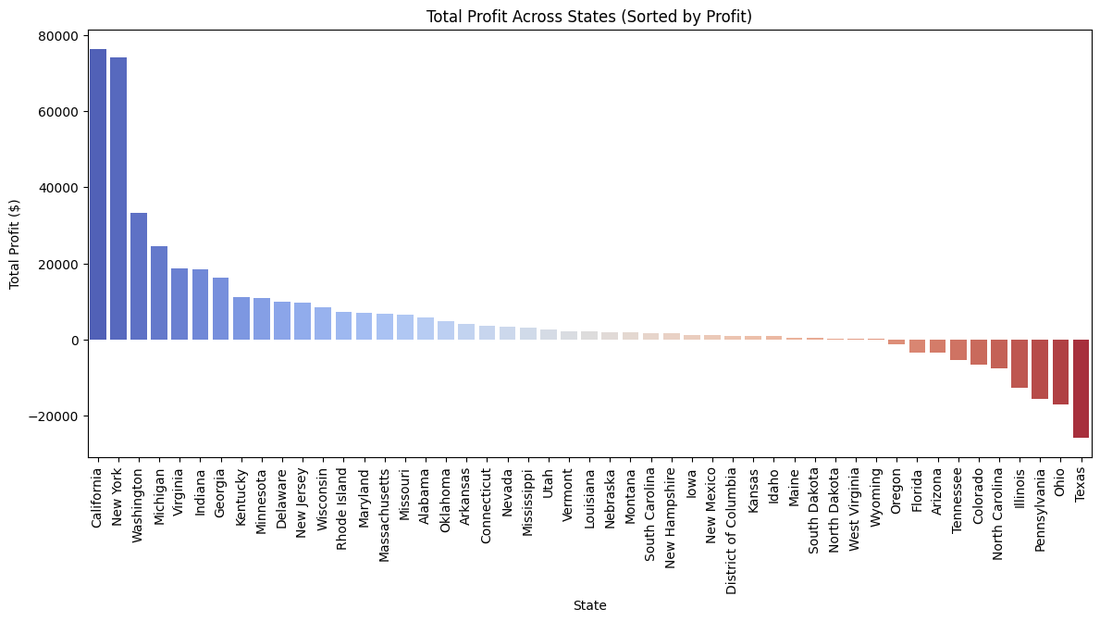

In [66]:
states = df_moj['State'].unique()
# Group profit values by state
profit_groups = [df_moj[df_moj['State'] == state]['Profit'] for state in states]

# Perform Kruskal-Wallis Test
kw_stat, kw_p = kruskal(*profit_groups)

# Display Results
print(f"Kruskal-Wallis Test: Statistic={kw_stat:.4f}, P-Value={kw_p:.4f}")
if kw_p < 0.05:
    print("Significant difference in profit distribution across states!")
else:
    print("No significant difference in profit distribution across states.")
print("\n\n")

# Violin Plot: Profit Distribution Across States
plt.figure(figsize=(14,6))
sns.violinplot(x="State", y="Profit", hue="State", data=df, inner="quartile", palette="viridis", legend=False)
plt.xticks(rotation=90)
plt.title("Profit Distribution Across States (Violin Plot)")
plt.xlabel("State")
plt.ylabel("Profit")
plt.show()
print("\n\n")

# Bar Chart: Mean Profit by State
plt.figure(figsize=(14,6))
df.groupby('State')['Profit'].mean().sort_values(ascending=False).plot(kind='bar', color='orange')
plt.title("Average Profit by State")
plt.xlabel("State")
plt.ylabel("Mean Profit")
plt.xticks(rotation=90)
plt.show()
print("\n\n")

# Group by State and Sum Profit, then Sort from Highest to Lowest Profit
profit_by_state = df.groupby('State')['Profit'].sum().reset_index()
profit_by_state = profit_by_state.sort_values(by='Profit', ascending=False)

# Bar Chart: Total Profit by State (Sorted)
plt.figure(figsize=(14,6))
sns.barplot(x="State", y="Profit", hue="State", data=profit_by_state, palette="coolwarm", dodge=False)
plt.xticks(rotation=90)
plt.title("Total Profit Across States (Sorted by Profit)")
plt.xlabel("State")
plt.ylabel("Total Profit ($)")
plt.show()

In [67]:
# Ensure State names match the required format for choropleth maps
# Using a dictionary to map full state names to abbreviations
state_abbreviations = {
    'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR', 'California': 'CA', 'Colorado': 'CO',
    'Connecticut': 'CT', 'Delaware': 'DE', 'Florida': 'FL', 'Georgia': 'GA', 'Hawaii': 'HI', 'Idaho': 'ID',
    'Illinois': 'IL', 'Indiana': 'IN', 'Iowa': 'IA', 'Kansas': 'KS', 'Kentucky': 'KY', 'Louisiana': 'LA',
    'Maine': 'ME', 'Maryland': 'MD', 'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN', 'Mississippi': 'MS',
    'Missouri': 'MO', 'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV', 'New Hampshire': 'NH', 'New Jersey': 'NJ',
    'New Mexico': 'NM', 'New York': 'NY', 'North Carolina': 'NC', 'North Dakota': 'ND', 'Ohio': 'OH', 'Oklahoma': 'OK',
    'Oregon': 'OR', 'Pennsylvania': 'PA', 'Rhode Island': 'RI', 'South Carolina': 'SC', 'South Dakota': 'SD',
    'Tennessee': 'TN', 'Texas': 'TX', 'Utah': 'UT', 'Vermont': 'VT', 'Virginia': 'VA', 'Washington': 'WA',
    'West Virginia': 'WV', 'Wisconsin': 'WI', 'Wyoming': 'WY'}

# Convert full state names to abbreviations
df['State'] = df['State'].map(state_abbreviations)

# Group by state and count the number of customers per state
customers_by_state = df['State'].value_counts().reset_index()
customers_by_state.columns = ['State', 'Customer Count']

# Choropleth Map: Number of Customers by State
fig1 = go.Figure(data=go.Choropleth(
    locations=customers_by_state['State'],
    z=customers_by_state['Customer Count'],
    locationmode='USA-states',
    colorscale='teal',
    zmin=1,
    zmax=customers_by_state['Customer Count'].max()))

fig1.update_layout(
    font=dict(size=14),
    title={
        'text': "Number of Customers by State Map",
        'y': 0.95,
        'x': 0.5},
    geo_scope='usa',)
fig1.show()


# Group by State and sum up Sales
sales_profit_by_state = df.groupby('State')[['Sales']].sum().reset_index()

# Choropleth Map: Total Sales by State
fig2 = go.Figure(data=go.Choropleth(
    locations=sales_profit_by_state['State'],
    z=sales_profit_by_state['Sales'],
    locationmode='USA-states',
    colorscale='teal',
))

fig2.update_layout(
    font=dict(size=14),
    title={
        'text': "Total Sales by State Map",
        'y': 0.95,
        'x': 0.5},
    geo_scope='usa',)
fig2.show()


# Group by state and sum Profit
data_sum_by_states = df.groupby('State')[['Profit']].sum().reset_index()
min_profit = data_sum_by_states['Profit'].min()
max_profit = data_sum_by_states['Profit'].max()
zero_position = abs(min_profit) / (max_profit - min_profit)

# Create the Choropleth Map for Total Profit by State
fig = go.Figure(data=go.Choropleth(
    locations=data_sum_by_states['State'],
    z=data_sum_by_states['Profit'],
    locationmode='USA-states',
    colorscale=[
        [0, "red"],
        [zero_position, "white"],
        [1, "green"]
    ],
    zmin=min_profit,
    zmax=max_profit,
    colorbar_title="Total Profit ($)"
))

fig.update_layout(
    font=dict(size=14),
    title={
        'text': "Total Profit by State (White = $0 Profit)",
        'y': 0.95,
        'x': 0.5,
        'xanchor': 'center',
        'yanchor': 'top'
    },
    geo_scope='usa',
)
fig.show()

[interactive Plotly figure - run the notebook to view]

[interactive Plotly figure - run the notebook to view]

[interactive Plotly figure - run the notebook to view]

In [68]:
cities = df_moj['City'].unique()
# Group profit values by city
profit_groups = [df_moj[df_moj['City'] == city]['Profit'] for city in cities]

# Perform Kruskal-Wallis Test
kw_stat, kw_p = kruskal(*profit_groups)

# Display Results
print(f"Kruskal-Wallis H Test: Statistic={kw_stat:.4f}, P-Value={kw_p:.4e}")

if kw_p < 0.05:
    print("Significant difference in profit distribution across cities!")
else:
    print("No significant difference in profit distribution across cities.")

Kruskal-Wallis H Test: Statistic=2490.8846, P-Value=1.3193e-250
Significant difference in profit distribution across cities!


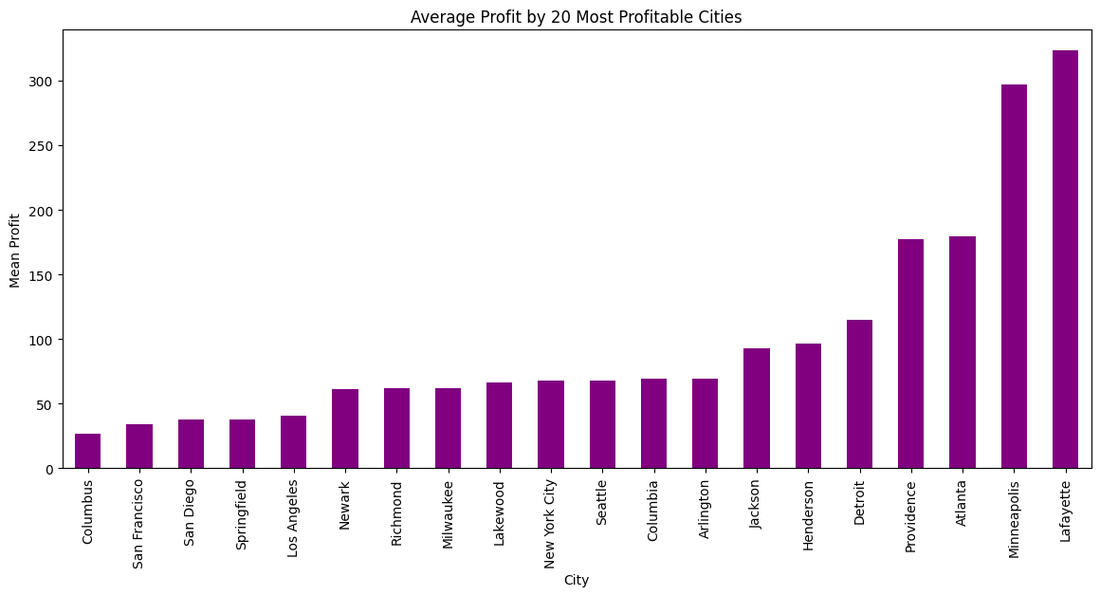

In [69]:
top_cities = df.groupby('City')['Profit'].sum().nlargest(20).index
df_top_cities = df[df['City'].isin(top_cities)]
# Bar Chart: Mean Profit by City
plt.figure(figsize=(14,6))
df_top_cities.groupby('City')['Profit'].mean().sort_values().plot(kind='bar', color='purple')
plt.title("Average Profit by 20 Most Profitable Cities")
plt.xlabel("City")
plt.ylabel("Mean Profit")
plt.xticks(rotation=90)
plt.show()

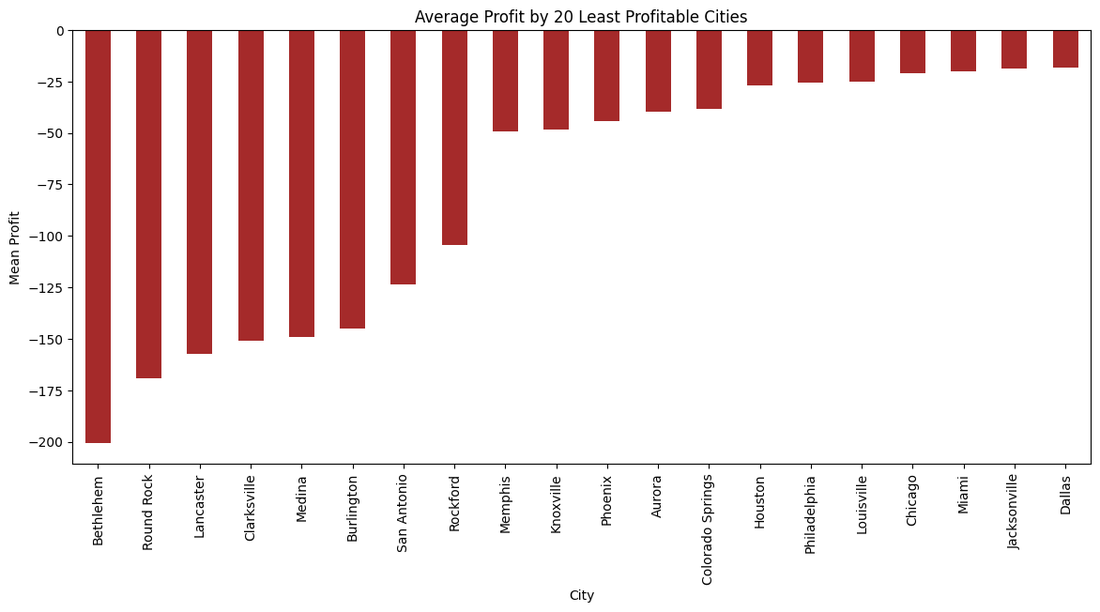

In [70]:
least_profitable_cities = df.groupby('City')['Profit'].sum().nsmallest(20).index
df_least_profitable = df[df['City'].isin(least_profitable_cities)]
# Bar Chart: Mean Profit by Least Profitable Cities
plt.figure(figsize=(14,6))
df_least_profitable.groupby('City')['Profit'].mean().sort_values().plot(kind='bar', color='brown')
plt.title("Average Profit by 20 Least Profitable Cities")
plt.xlabel("City")
plt.ylabel("Mean Profit")
plt.xticks(rotation=90)
plt.show()

Spearman's Rank Correlation (Sales vs. Profit): 0.5187
P-Value: 0.0000
Significant correlation between Sales and Profit!





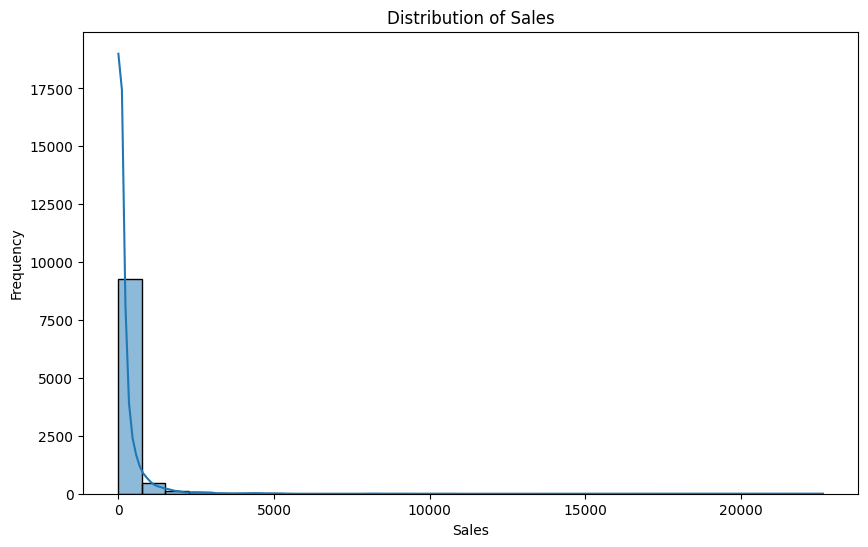

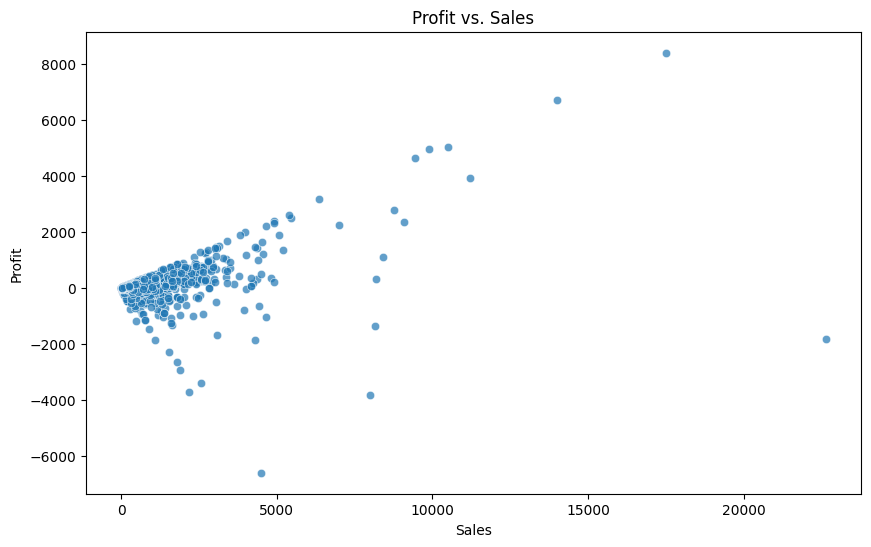

In [71]:
spearman_corr_sales, p_value_sales = spearmanr(df_moj['Sales'], df_moj['Profit'])

# Display Results
print(f"Spearman's Rank Correlation (Sales vs. Profit): {spearman_corr_sales:.4f}")
print(f"P-Value: {p_value_sales:.4f}")
if p_value_sales < 0.05:
    print("Significant correlation between Sales and Profit!")
else:
    print("No significant correlation between Sales and Profit.")
print("\n\n")

# Histogram of Sales Distribution
plt.figure(figsize=(10, 6))
sns.histplot(df_moj['Sales'], bins=30, kde=True)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()
print("\n\n")

# Scatter plot of Profit vs. Sales
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df_moj['Sales'], y=df_moj['Profit'], alpha=0.7)
plt.title("Profit vs. Sales")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()
print("\n\n")

Spearman's Rank Correlation (Quantity vs. Profit): 0.2344
P-Value: 0.0000
Significant correlation between Quantity and Profit!





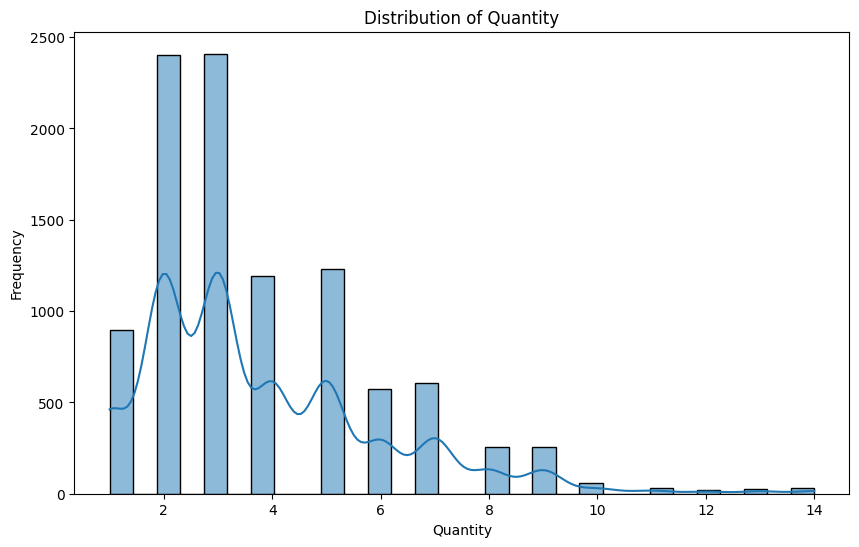

In [72]:
spearman_corr_quantity, p_value_quantity = spearmanr(df_moj['Quantity'], df_moj['Profit'])

print(f"Spearman's Rank Correlation (Quantity vs. Profit): {spearman_corr_quantity:.4f}")
print(f"P-Value: {p_value_quantity:.4f}")
if p_value_quantity < 0.05:
    print("Significant correlation between Quantity and Profit!")
else:
    print("No significant correlation between Quantity and Profit.")
print("\n\n")

# Histogram of Quantity Distribution
plt.figure(figsize=(10, 6))
sns.histplot(df_moj['Quantity'], bins=30, kde=True)
plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.show()

Spearman's Rank Correlation: -0.5432
P-Value: 0.0000
Significant correlation between Discount and Profit!





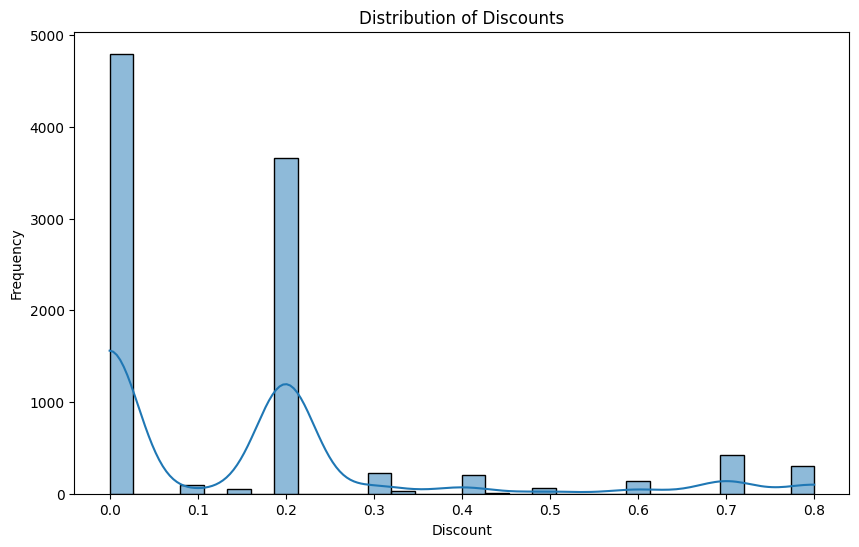

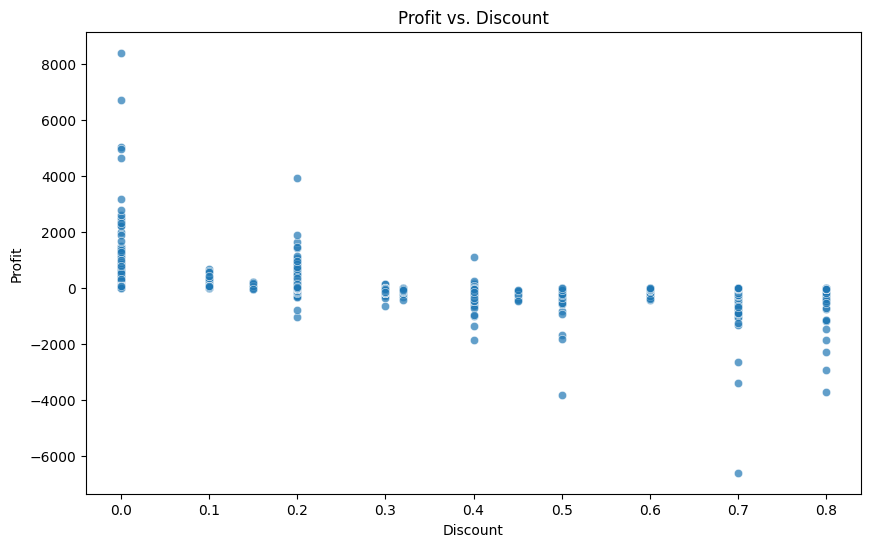

In [73]:
# Compute Spearman's Rank Correlation
spearman_corr, p_value = spearmanr(df_moj['Discount'], df_moj['Profit'])

# Display Results
print(f"Spearman's Rank Correlation: {spearman_corr:.4f}")
print(f"P-Value: {p_value:.4f}")
if p_value < 0.05:
    print("Significant correlation between Discount and Profit!")
else:
    print("No significant correlation between Discount and Profit.")
print("\n\n")


# Visualization 2: Histogram of Discounts
plt.figure(figsize=(10, 6))
sns.histplot(df['Discount'], bins=30, kde=True)
plt.title("Distribution of Discounts")
plt.xlabel("Discount")
plt.ylabel("Frequency")
plt.show()
print("\n\n")

# Visualization 3: Scatter plot of Profit vs. Discount
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['Discount'], y=df['Profit'], alpha=0.7)
plt.title("Profit vs. Discount")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

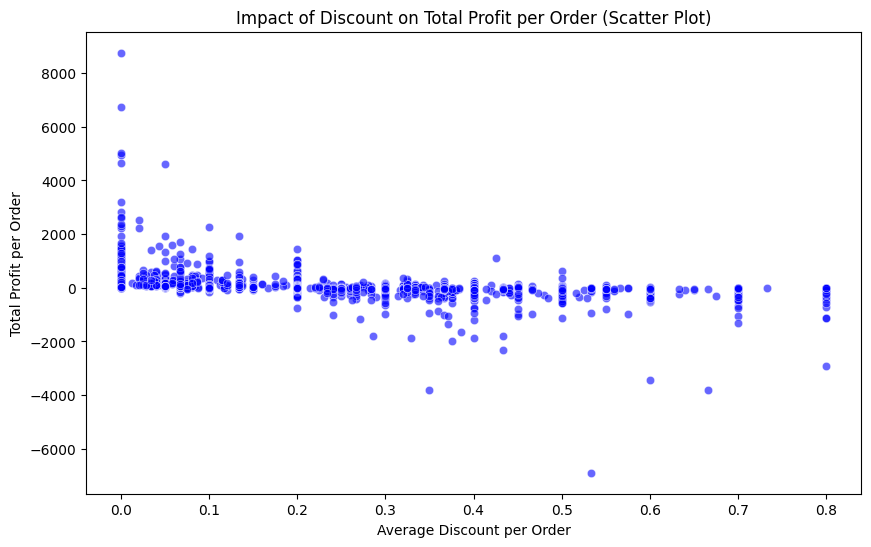

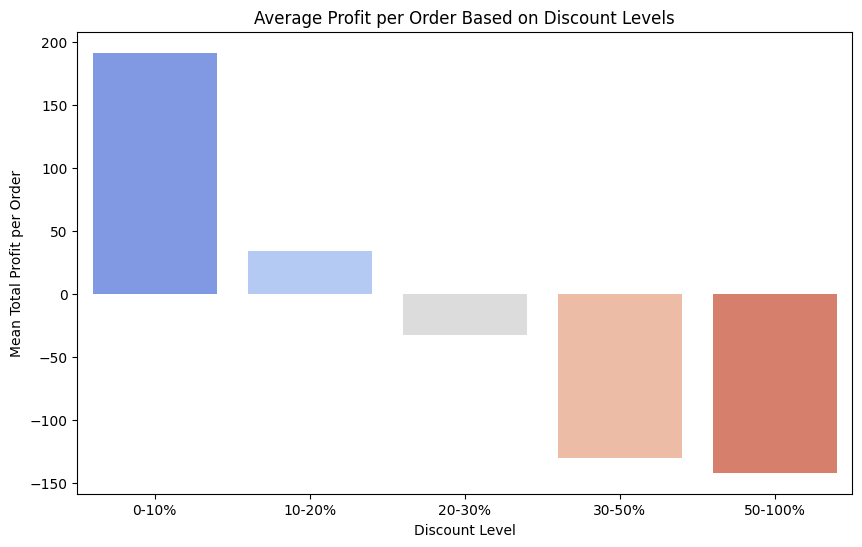

In [74]:
# Grouping data by Order ID and calculating the average discount and total profit per order
order_analysis = df.groupby('Order ID').agg(avg_discount=('Discount', 'mean'),  total_profit=('Profit', 'sum')).reset_index()

# Scatter Plot: Relationship Between Discount & Profit at Order Level
plt.figure(figsize=(10,6))
sns.scatterplot(x=order_analysis['avg_discount'], y=order_analysis['total_profit'], alpha=0.6, color='blue')
plt.title("Impact of Discount on Total Profit per Order (Scatter Plot)")
plt.xlabel("Average Discount per Order")
plt.ylabel("Total Profit per Order")
plt.show()
print("\n\n")

#Bar Plot: Categorizing Discounts into Groups
order_analysis['Discount Group'] = pd.cut(order_analysis['avg_discount'], bins=[0, 0.1, 0.2, 0.3, 0.5, 1],
labels=['0-10%', '10-20%', '20-30%', '30-50%', '50-100%'])

plt.figure(figsize=(10,6))
sns.barplot(x="Discount Group", y="total_profit", hue="Discount Group", data=order_analysis, estimator="mean", errorbar=None, palette="coolwarm", legend=False)
plt.title("Average Profit per Order Based on Discount Levels")
plt.xlabel("Discount Level")
plt.ylabel("Mean Total Profit per Order")
plt.show()

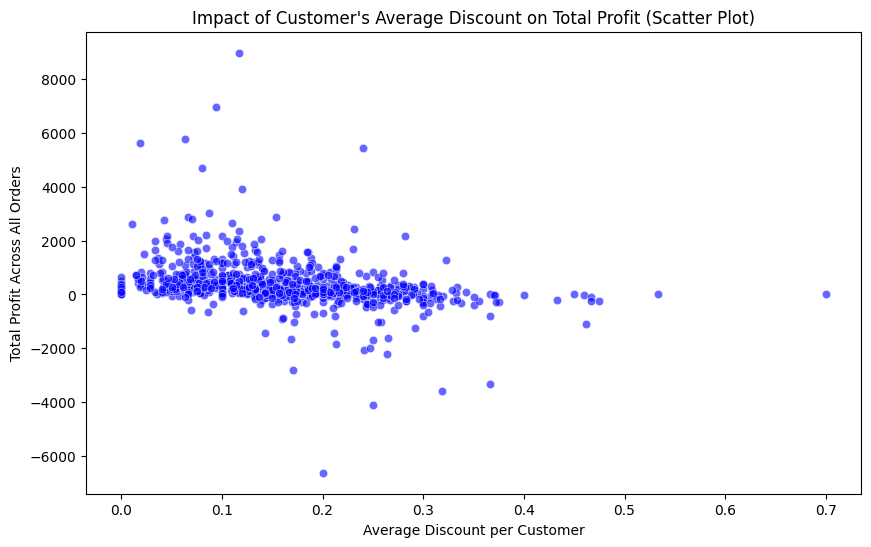

In [75]:
# Grouping data by Customer ID and calculating the average discount and total profit across all orders per customer
customer_analysis = df.groupby('Customer ID').agg(
    avg_discount=('Discount', 'mean'),  # Average discount per customer
    total_profit=('Profit', 'sum')  # Total profit across all orders for each customer
).reset_index()

# Scatter Plot: Relationship Between Customer's Average Discount & Total Profit
plt.figure(figsize=(10,6))
sns.scatterplot(x=customer_analysis['avg_discount'], y=customer_analysis['total_profit'], alpha=0.6, color='blue')
plt.title("Impact of Customer's Average Discount on Total Profit (Scatter Plot)")
plt.xlabel("Average Discount per Customer")
plt.ylabel("Total Profit Across All Orders")
plt.show()

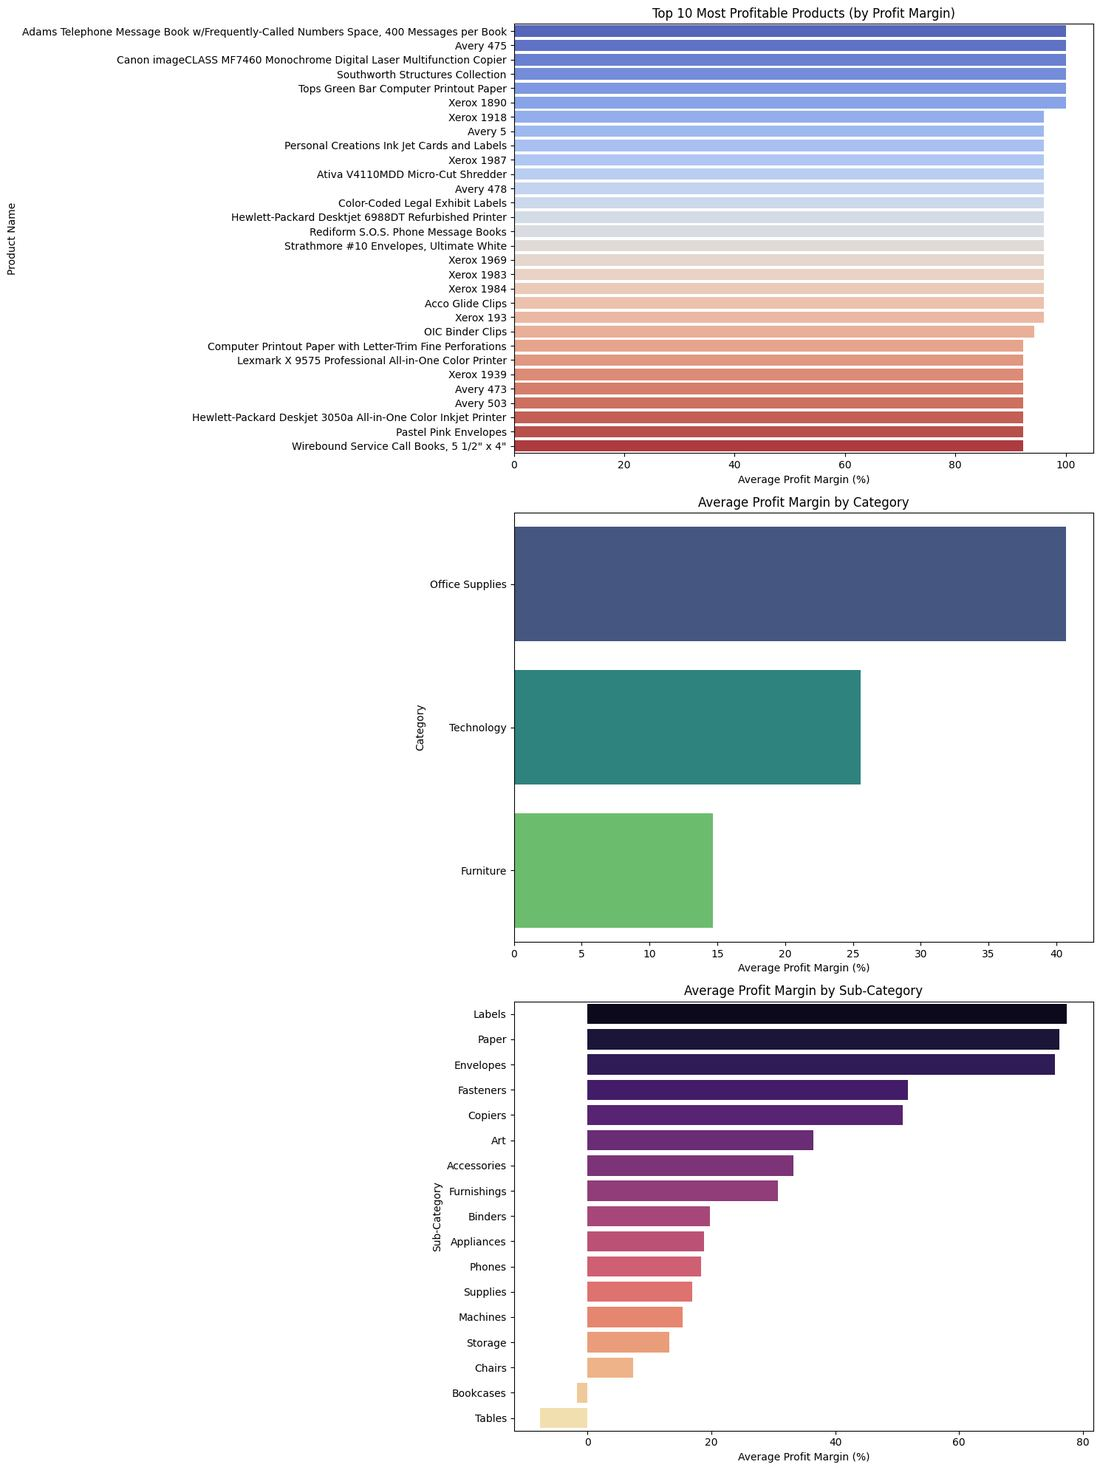

In [76]:
top_profitable_products = df.groupby("Product Name")["Profit Margin (%)"].mean().nlargest(30)

# Calculate Average Profit Margin by Category
category_profit_margin = df.groupby("Category")["Profit Margin (%)"].mean().sort_values(ascending=False)

# Calculate Average Profit Margin by Sub-Category
sub_category_profit_margin = df.groupby("Sub-Category")["Profit Margin (%)"].mean().sort_values(ascending=False)

plt.figure(figsize=(15, 20))

# Bar Plot: Top 10 Most Profitable Products by Profit Margin
plt.subplot(3, 1, 1)
sns.barplot(x=top_profitable_products.values, y=top_profitable_products.index, hue=top_profitable_products.index, palette="coolwarm", legend=False)
plt.title("Top 10 Most Profitable Products (by Profit Margin)")
plt.xlabel("Average Profit Margin (%)")
plt.ylabel("Product Name")


# Bar Plot: Average Profit Margin by Product Category
plt.subplot(3, 1, 2)
sns.barplot(x=category_profit_margin.values, y=category_profit_margin.index, hue=category_profit_margin.index, palette="viridis", legend=False)
plt.title("Average Profit Margin by Category")
plt.xlabel("Average Profit Margin (%)")
plt.ylabel("Category")


# Bar Plot: Average Profit Margin by Sub-Category
plt.subplot(3, 1, 3)
sns.barplot(x=sub_category_profit_margin.values, y=sub_category_profit_margin.index, hue=sub_category_profit_margin.index, palette="magma", legend=False)
plt.title("Average Profit Margin by Sub-Category")
plt.xlabel("Average Profit Margin (%)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

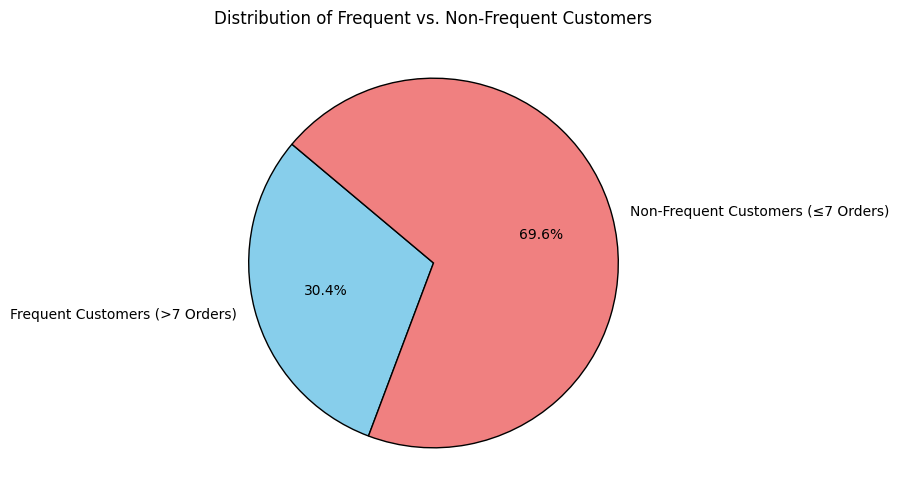

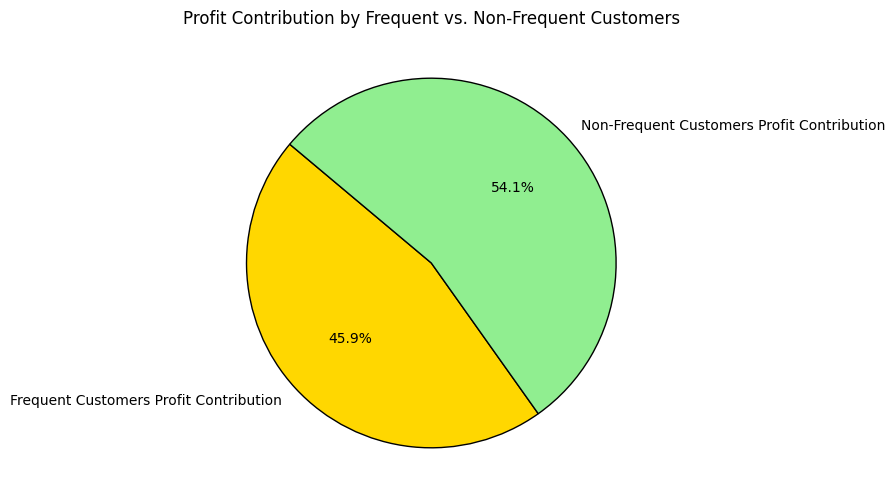

In [77]:
# Distribution of Frequent vs. Non-Frequent Customers
# Count the number of unique orders per customer
customer_order_counts = df.groupby('Customer ID')['Order ID'].nunique()

# Define frequent customers as those with more than 7 unique orders
frequent_customers = customer_order_counts[customer_order_counts > 7].count()
non_frequent_customers = customer_order_counts[customer_order_counts <= 7].count()

# Prepare data for pie chart 1 (Customer Distribution)
labels1 = ['Frequent Customers (>7 Orders)', 'Non-Frequent Customers (≤7 Orders)']
sizes1 = [frequent_customers, non_frequent_customers]
colors1 = ['skyblue', 'lightcoral']

# Create Pie Chart 1: Distribution of Frequent vs. Non-Frequent Customers
plt.figure(figsize=(8, 6))
plt.pie(sizes1, labels=labels1, autopct='%1.1f%%', colors=colors1, startangle=140, wedgeprops={'edgecolor': 'black'})
plt.title("Distribution of Frequent vs. Non-Frequent Customers")
plt.show()

print("\n\n")
# Profit Contribution by Frequent vs. Non-Frequent Customers
# Calculate total profit contributed by frequent and non-frequent customers
frequent_profit = df[df['Customer ID'].isin(customer_order_counts[customer_order_counts > 7].index)]['Profit'].sum()
non_frequent_profit = df[df['Customer ID'].isin(customer_order_counts[customer_order_counts <= 7].index)]['Profit'].sum()

# Prepare data for pie chart 2 (Profit Contribution)
labels2 = ['Frequent Customers Profit Contribution', 'Non-Frequent Customers Profit Contribution']
sizes2 = [frequent_profit, non_frequent_profit]
colors2 = ['gold', 'lightgreen']

# Create Pie Chart 2: Profit Contribution
plt.figure(figsize=(8, 6))
plt.pie(sizes2, labels=labels2, autopct='%1.1f%%', colors=colors2, startangle=140, wedgeprops={'edgecolor': 'black'})
plt.title("Profit Contribution by Frequent vs. Non-Frequent Customers")
plt.show()

Top 20% most profitable customers contribute 59.02% of all positive profit!
These customers are crucial for maximizing business growth!


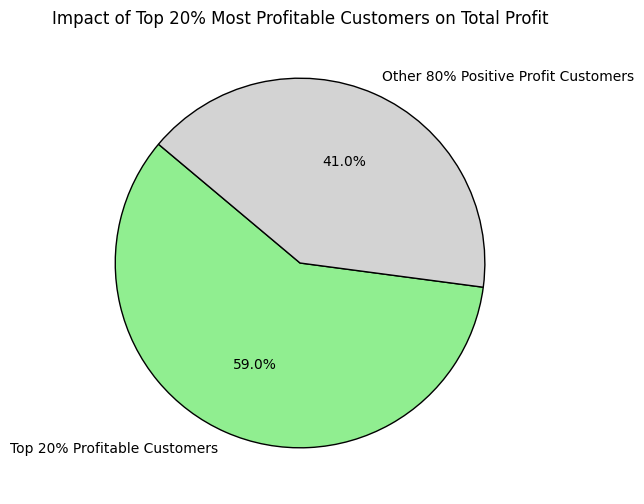

Bottom 20% least profitable customers contribute 71.10% of all negative profit!
These customers are significantly responsible for losses.


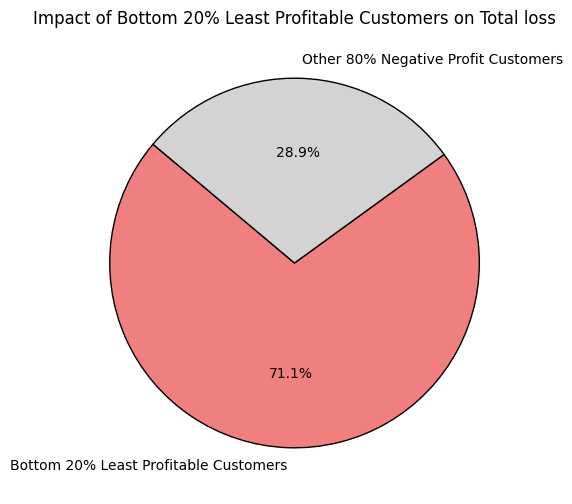

In [78]:
# Impact of Top 20% Most Profitable Customers on Total Profit
# Calculate total profit per customer
df2 = df.groupby('Customer ID')['Profit'].sum().reset_index()

# Separate customers into positive and negative profit groups
positive_profit_customers = df2[df2['Profit'] > 0]  # Only customers with positive profit
negative_profit_customers = df2[df2['Profit'] < 0]  # Only customers with negative profit
top_20_percent_threshold = positive_profit_customers['Profit'].quantile(0.8, interpolation='higher')
top_20_percent_customers = positive_profit_customers[positive_profit_customers['Profit'] >= top_20_percent_threshold]
top_20_percent_profit = (top_20_percent_customers['Profit'].sum() / positive_profit_customers['Profit'].sum()) * 100

print(f"Top 20% most profitable customers contribute {top_20_percent_profit:.2f}% of all positive profit!")
print("These customers are crucial for maximizing business growth!")

# Pie Chart (Only for Positive Profit)
positive_profit_contribution = [
    top_20_percent_customers['Profit'].sum(),
    positive_profit_customers['Profit'].sum() - top_20_percent_customers['Profit'].sum()]

labels_positive = ['Top 20% Profitable Customers', 'Other 80% Positive Profit Customers']
colors_positive = ['lightgreen', 'lightgrey']
plt.figure(figsize=(8, 6))
plt.pie(positive_profit_contribution, labels=labels_positive, autopct='%1.1f%%', colors=colors_positive, startangle=140, wedgeprops={'edgecolor': 'black'})
plt.title("Impact of Top 20% Most Profitable Customers on Total Profit")
plt.show()


# Impact of Bottom 20% Least Profitable Customers on Total loss
# Find the 20th percentile threshold for **Bottom 20% Least Profitable Customers (Only Negative Profit)**
bottom_20_percent_threshold = negative_profit_customers['Profit'].quantile(0.2, interpolation='lower')
bottom_20_percent_customers = negative_profit_customers[negative_profit_customers['Profit'] <= bottom_20_percent_threshold]
bottom_20_percent_loss = (bottom_20_percent_customers['Profit'].sum() / negative_profit_customers['Profit'].sum()) * 100

print(f"Bottom 20% least profitable customers contribute {abs(bottom_20_percent_loss):.2f}% of all negative profit!")
print("These customers are significantly responsible for losses.")

# Pie Chart (Only for Negative Profit)
negative_profit_contribution = [
    abs(bottom_20_percent_customers['Profit'].sum()),
    abs(negative_profit_customers['Profit'].sum()) - abs(bottom_20_percent_customers['Profit'].sum())]

labels_negative = ['Bottom 20% Least Profitable Customers', 'Other 80% Negative Profit Customers']
colors_negative = ['lightcoral', 'lightgrey']
plt.figure(figsize=(8, 6))
plt.pie(negative_profit_contribution, labels=labels_negative, autopct='%1.1f%%', colors=colors_negative, startangle=140, wedgeprops={'edgecolor': 'black'})
plt.title("Impact of Bottom 20% Least Profitable Customers on Total loss")
plt.show()

In [79]:
# Sales by Days of the Week
# Extract the day of the week
df['Day of Week'] = df['Order Date'].dt.day_name()

# Group sales by day of the week
daily_sales = df.groupby('Day of Week')['Sales'].sum().reset_index()

# Define the correct order of days
days_of_week = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Convert 'Day of Week' to categorical with the correct order
daily_sales['Day of Week'] = pd.Categorical(daily_sales['Day of Week'], categories=days_of_week, ordered=True)

# Sort values based on the correct day order
daily_sales = daily_sales.sort_values(by='Day of Week')
color1 = 'skyblue'

# bar chart
fig = go.Figure(data=[go.Bar(
    x=daily_sales['Day of Week'],
    y=daily_sales['Sales'],
    marker_color=color1,
    marker_line_color='rgb(8,48,107)',
    marker_line_width=1.5,
    opacity=0.6
)])
fig.update_layout(
    title='Sales by Days of the Week',
    title_x=0.45,
    width=1300,
    title_font=dict(size=24, family="Arial", color="black"),
    xaxis_title="Day of the Week",
    yaxis_title="Total Sales",
    template="plotly_white"
)
fig.show()

[interactive Plotly figure - run the notebook to view]

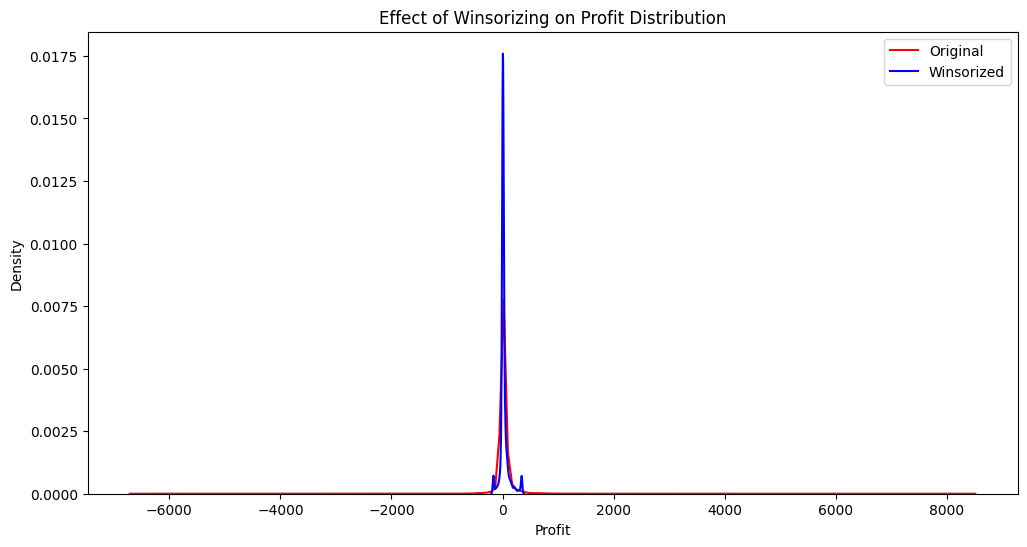

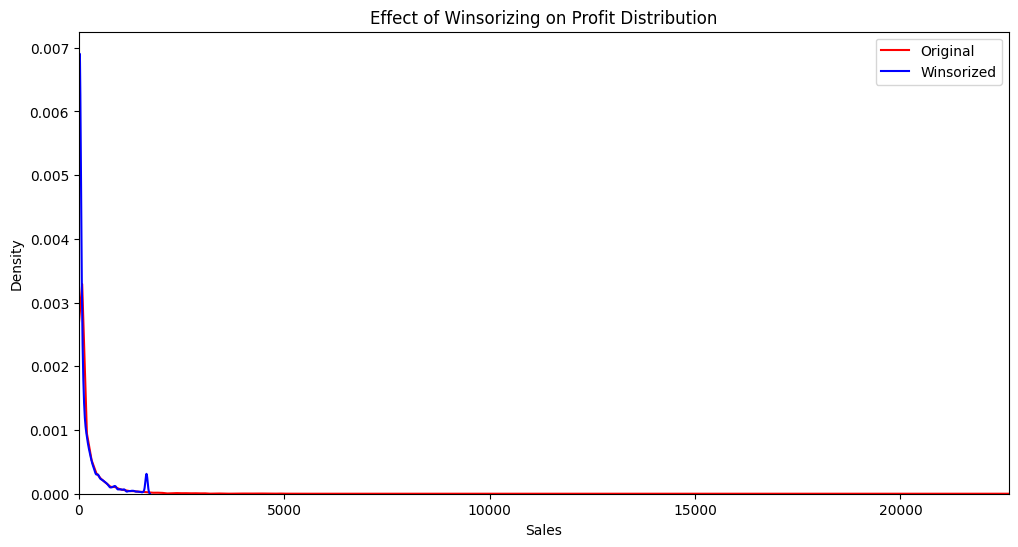

Original dataset size: 9993, After removing outliers: 9993

Descriptive Statistics Completed! Processed dataset saved.


In [80]:
# Outlier Detection and Removal
# IQR method
#Q1 = df[['Sales', 'Profit', 'Quantity', 'Discount']].quantile(0.25)
#Q3 = df[['Sales', 'Profit', 'Quantity', 'Discount']].quantile(0.75)
#IQR = Q3 - Q1

# Defining bounds
#lower_bound = Q1 - 1.5 * IQR
#upper_bound = Q3 + 1.5 * IQR

# Filtering outliers
#df_no_outliers = df[~((df[['Sales', 'Profit', 'Quantity', 'Discount']] < lower_bound) |
#                      (df[['Sales', 'Profit', 'Quantity', 'Discount']] > upper_bound)).any(axis=1)]


# Define Winsorizing
df_with_outliers = df.copy()
df_no_outliers = df.copy()
df_no_outliers['Profit'] = winsorize(df['Profit'], limits=[0.02, 0.02])  # 2% from each side
df_no_outliers['Sales'] = winsorize(df['Sales'], limits=[0.00, 0.02])  # 2% from one side

# Visualize Before & After
plt.figure(figsize=(12,6))
sns.kdeplot(df['Profit'], label="Original", color='red')
sns.kdeplot(df_no_outliers['Profit'], label="Winsorized", color='blue')
plt.title("Effect of Winsorizing on Profit Distribution")
plt.legend()
plt.show()

plt.figure(figsize=(12, 6))
sns.kdeplot(df['Sales'], label="Original", color='red', bw_adjust=0.5)
sns.kdeplot(df_no_outliers['Sales'], label="Winsorized", color='blue', bw_adjust=0.5)
plt.xlim(0, df['Sales'].max())  # Force x-axis to start at 0
plt.title("Effect of Winsorizing on Profit Distribution")
plt.legend()
plt.show()

print(f"Original dataset size: {df.shape[0]}, After removing outliers: {df_no_outliers.shape[0]}")

# Save dataset after outlier removal for next steps
df_no_outliers.to_csv('../data/Nout_Superstore.csv', index=False)
print("\nDescriptive Statistics Completed! Processed dataset saved.")

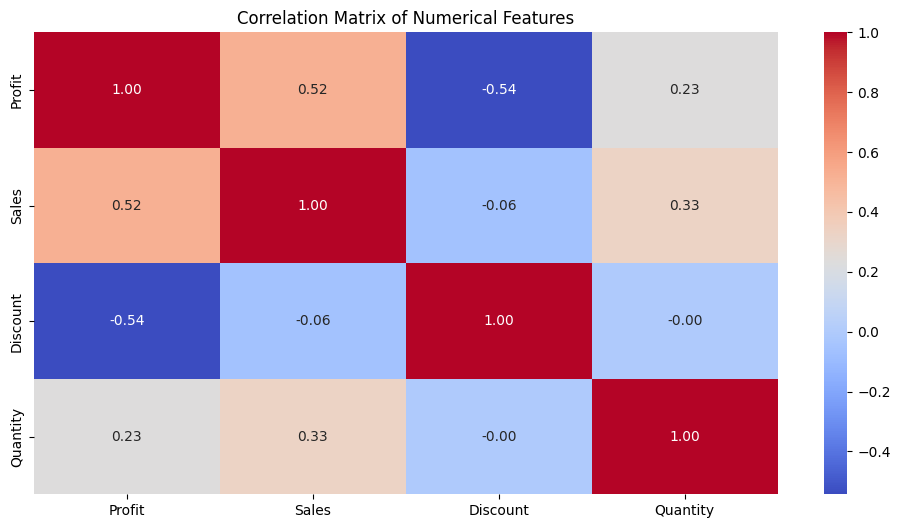

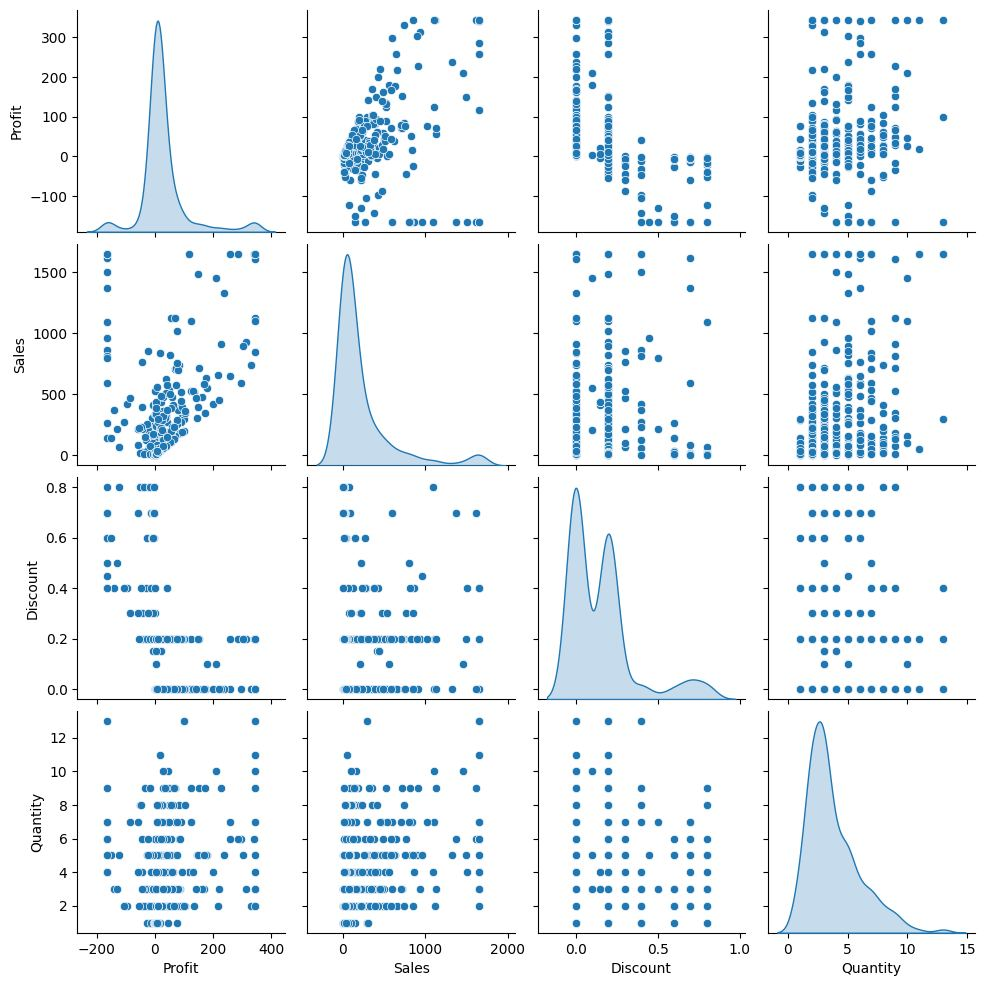

In [81]:
df = pd.read_csv('../data/Nout_Superstore.csv')

# Select numerical columns for correlation analysis
numerical_columns = ['Profit','Sales','Discount','Quantity']

# Compute the correlation matrix using Spearman method
plt.figure(figsize=(12, 6))
corr_matrix = df_moj[numerical_columns].corr(method='spearman')

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix of Numerical Features")
plt.show()
print("\n\n")

# Pairwise correlation scatter plots for relevant numercial variables
num_features = ['Profit','Sales', 'Discount','Quantity']
df_sample = df[num_features].sample(500, random_state=42)
sns.pairplot(df_sample[num_features], diag_kind='kde')
plt.show()
print("\n\n")

# Save updated dataset
#df.to_csv('../data/EDA_Superstore.csv', index=False)

In [82]:
# Load dataset
#df = pd.read_csv('../data/EDA_Superstore.csv')


In [83]:
# Select numerical features to standardize
numerical_features = ['Sales', 'Quantity', 'Discount', 'Profit']

scaler = StandardScaler()
df_standardized = df.copy()

# Apply Standardization (mean=0, std=1)
df_standardized[numerical_features] = scaler.fit_transform(df_standardized[numerical_features])

# Display the first few rows of the standardized dataset
df_standardized.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Segment,City,State,Region,Product ID,...,Product Name,Sales,Quantity,Discount,Profit,Profit Margin (%),Profit per Order,Delivery Days,Year,Day of Week
0,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,Henderson,KY,South,FUR-BO-10001798,...,Bush Somerset Collection Bookcase,0.190177,-0.804370,-0.756554,0.220182,19.047619,20.9568,3,2016,Tuesday
1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Consumer,Henderson,KY,South,FUR-CH-10000454,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",1.583021,-0.354939,-0.756554,2.565654,42.857143,73.1940,3,2016,Tuesday
2,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Corporate,Los Angeles,CA,West,OFF-LA-10000240,...,Self-Adhesive Address Labels for Typewriters b...,-0.542845,-0.804370,-0.756554,-0.242425,88.679245,3.4357,4,2016,Sunday
3,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,Fort Lauderdale,FL,South,FUR-TA-10000577,...,Bretford CR4500 Series Slim Rectangular Table,2.251725,0.543922,1.423182,-2.509203,-28.571429,-76.6062,7,2015,Sunday
4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Consumer,Fort Lauderdale,FL,South,OFF-ST-10000760,...,Eldon Fold 'N Roll Cart System,-0.519883,-0.804370,0.212218,-0.299917,12.676056,1.2582,7,2015,Sunday


In [84]:
# Encoding for standardize data (for using categorical data)
df_encoded = pd.get_dummies(df_standardized, columns=['Ship Mode', 'Segment', 'Category', 'Sub-Category', 'Region', 'State','City'], drop_first=False)

# Encoding for data with outlier (for using categorical data)
df_Random = pd.get_dummies(df_no_outliers, columns=['Ship Mode', 'Segment', 'Category', 'Sub-Category', 'Region', 'State','City'], drop_first=False)
df_Random.head()

,Order ID,Order Date,Ship Date,Customer ID,Product ID,Product Name,Sales,Quantity,Discount,Profit,...,City_Wilmington,City_Wilson,City_Woodbury,City_Woodland,City_Woodstock,City_Woonsocket,City_Yonkers,City_York,City_Yucaipa,City_Yuma
0,CA-2016-152156,2016-11-08,2016-11-11,CG-12520,FUR-BO-10001798,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,...,False,False,False,False,False,False,False,False,False,False
1,CA-2016-152156,2016-11-08,2016-11-11,CG-12520,FUR-CH-10000454,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,...,False,False,False,False,False,False,False,False,False,False
2,CA-2016-138688,2016-06-12,2016-06-16,DV-13045,OFF-LA-10000240,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,...,False,False,False,False,False,False,False,False,False,False
3,US-2015-108966,2015-10-11,2015-10-18,SO-20335,FUR-TA-10000577,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-164.8360,...,False,False,False,False,False,False,False,False,False,False
4,US-2015-108966,2015-10-11,2015-10-18,SO-20335,OFF-ST-10000760,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,...,False,False,False,False,False,False,False,False,False,False


Linear Regression - Mean Squared Error: 0.5520
Linear Regression - R-squared: 0.4967
Random Forest - Mean Squared Error: 697.4520
Random Forest - R-squared: 0.8892


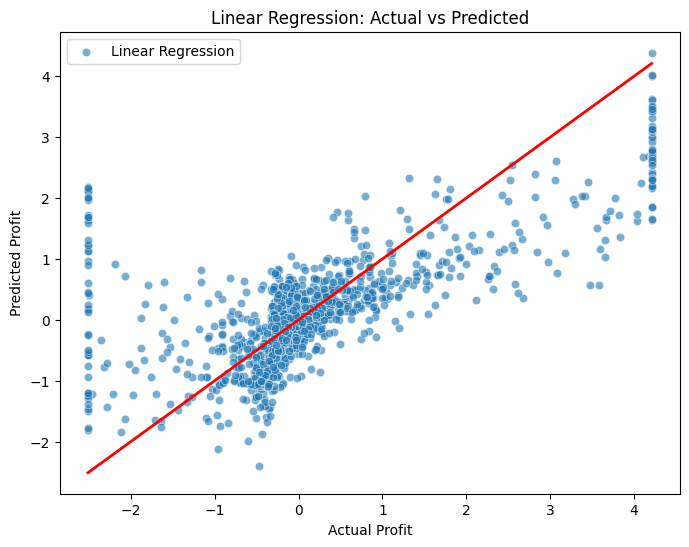

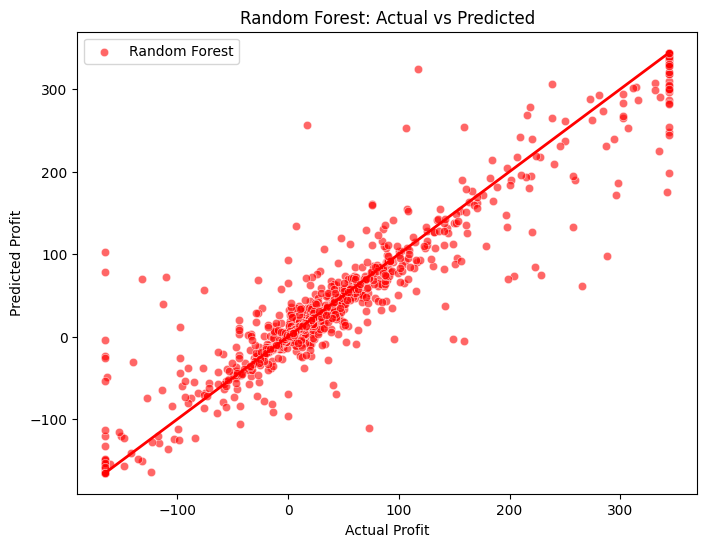


Feature Importance from Random Forest:
                    Feature  Importance
0                     Sales      0.4685
2                  Discount      0.3206
20     Sub-Category_Copiers      0.0266
17     Sub-Category_Binders      0.0235
28     Sub-Category_Storage      0.0221
..                      ...         ...
342          City_Littleton      0.0000
105      City_Atlantic City      0.0000
100  City_Arlington Heights      0.0000
362            City_Margate      0.0000
250          City_Gladstone      0.0000

[614 rows x 2 columns]

Regression Model Coefficients:
                   Feature  Coefficient
0                    Sales     0.630896
1                 Quantity    -0.000375
2                 Discount    -0.361563
3                     Year     0.005632
4    Ship Mode_First Class    -0.005759
..                     ...          ...
609        City_Woonsocket    -0.076120
610           City_Yonkers     0.087980
611              City_York     0.068014
612           City_Yucai

In [85]:
# Modeling
# Linear Regression model:
feature_columns = [col for col in df_encoded.columns if col not in ['Order ID', 'Order Date', 'Ship Date', 'Customer ID', 'Product ID', 'Profit', 'Product Name', 'Profit per Order', 'Profit Margin (%)', 'Delivery Days','Ship Mode', 'Segment', 'Day of Week']]

X = df_encoded[feature_columns]
y = df_encoded['Profit']
# Splitting data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fitting the regression model
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)
lin_pred = lin_model.predict(X_test)

# Linear Regression Evaluation
lin_mse = mean_squared_error(y_test, lin_pred)
lin_r2 = r2_score(y_test, lin_pred)
print(f"Linear Regression - Mean Squared Error: {lin_mse:.4f}")
print(f"Linear Regression - R-squared: {lin_r2:.4f}")

# Random Forest model
feature_column = [col for col in df_Random.columns if col not in ['Order ID', 'Order Date', 'Ship Date', 'Customer ID', 'Product ID', 'Profit', 'Product Name', 'Profit per Order', 'Profit Margin (%)', 'Delivery Days', 'Ship Mode', 'Day of Week']]

T = df_Random[feature_column]
P = df_Random['Profit']

# Splitting data into training and test sets
T_train, T_test, P_train, P_test = train_test_split(T, P, test_size=0.2, random_state=42)

# Random Forest Regressor Model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(T_train, P_train)
rf_pred = rf_model.predict(T_test)

# Random Forest Evaluation
rf_mse = mean_squared_error(P_test, rf_pred)
rf_r2 = r2_score(P_test, rf_pred)
print(f"Random Forest - Mean Squared Error: {rf_mse:.4f}")
print(f"Random Forest - R-squared: {rf_r2:.4f}")

plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=lin_pred, alpha=0.6, label='Linear Regression')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r', lw=2)
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.show()
print("\n\n")

plt.figure(figsize=(8,6))
sns.scatterplot(x=P_test, y=rf_pred, alpha=0.6, label='Random Forest', color='red')
plt.plot([P_test.min(), P_test.max()], [P_test.min(), P_test.max()], 'r', lw=2)
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("Random Forest: Actual vs Predicted")
plt.legend()
plt.show()

# Random Forest Model Feature Importance
feature_importance = pd.DataFrame({'Feature': T.columns, 'Importance': rf_model.feature_importances_})
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
feature_importance['Importance'] = feature_importance['Importance'].apply(lambda x: round(x, 4))
print("\nFeature Importance from Random Forest:")
print(feature_importance)

# Linear Regression Model Coefficients
coefficients = pd.DataFrame({'Feature': X.columns, 'Coefficient': lin_model.coef_})
print("\nRegression Model Coefficients:")
print(coefficients)

# Saving the model results
df_results = pd.DataFrame({'Actual': y_test, 'Linear_Predicted': lin_pred, 'RF_Predicted': rf_pred})

In [86]:
# evaluate of models
def evaluate_model(y_test, y_pred, model_name):
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    print(f"\n{model_name} Performance:")
    print(f"R² Score: {r2:.4f}")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    return r2, mae, rmse

# Evaluate Linear Regression Model
print("Linear Regression Results:")
lin_r2, lin_mae, lin_rmse = evaluate_model(y_test, lin_pred, "Linear Regression")

# Evaluate Random Forest Model
print("Random Forest Results:")
rf_r2, rf_mae, rf_rmse = evaluate_model(P_test, rf_pred, "Random Forest")

Linear Regression Results:

Linear Regression Performance:
R² Score: 0.4967
Mean Absolute Error (MAE): 0.4467
Root Mean Squared Error (RMSE): 0.7430
Random Forest Results:

Random Forest Performance:
R² Score: 0.8892
Mean Absolute Error (MAE): 10.2827
Root Mean Squared Error (RMSE): 26.4093
